# Predicting hydropower unit commitment for the Tokke–Vinje system

**TDT4173 Modern Machine Learning in Practice: course project report**

**Kaggle team:** TODO "[<group number>] <team name>"

| Name | Student ID |
|---|---|
| TODO | TODO |

**Final selected submissions:** `Short_notebook_1.ipynb` (LightGBM, public LB 0.99414) and
`Short_notebook_2.ipynb` (XGBoost, public LB 0.99429).

---

**About this notebook.** Every section has a *disposition* (marked 📝) that describes what the
final text will say and why, followed by the code that produces the section's figures and
tables. The code runs from the repository root on the cached features and saved validation
predictions (`features/`, `experiments/`). The graders will not run it, so it must be saved
with its outputs.

### Contents
1. Introduction
2. Exploratory data analysis
3. Validation strategy
4. Feature engineering
5. Models (predictor types)
6. Hyperparameters
7. Model interpretation
8. Results
9. Discussion and lessons learned
10. References

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import cv, models
from src.data import HOURS, UPSTREAM, DOWNSTREAM, load_data, plant_of, upstream_wv, downstream_wv, week_prices
from src.features import build_matrix, load_group

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
pd.set_option("display.max_colwidth", 120)


# Export for the LaTeX report (report/): every numbered figure and table is also saved there.
# The section .tex files include them, so re-running this notebook updates the report's figures and tables.
REPORT_DIR = ROOT / "report"
(REPORT_DIR / "figures").mkdir(parents=True, exist_ok=True)
(REPORT_DIR / "tables").mkdir(parents=True, exist_ok=True)


def show_figure(fig_id):
    """Save the current figure as report/figures/fig_<id>.pdf, then show it. The 'Figure x.y: ...' title is left
    out of the saved file because LaTeX adds the caption; its text is stored in captions.json as a draft caption."""
    fig = plt.gcf()
    titles = [t for t in [fig._suptitle, *(ax.title for ax in fig.axes)] if t is not None and t.get_text().startswith("Figure ")]
    texts = [t.get_text() for t in titles]
    for t in titles:
        t.set_text("")
    fig.savefig(REPORT_DIR / "figures" / f"fig_{fig_id.replace('.', '_')}.pdf", bbox_inches="tight")
    for t, text in zip(titles, texts):
        t.set_text(text)
    captions_file = REPORT_DIR / "figures" / "captions.json"
    captions = json.loads(captions_file.read_text(encoding="utf-8")) if captions_file.exists() else {}
    captions[fig_id] = texts[0].split(": ", 1)[-1] if texts else ""
    captions_file.write_text(json.dumps(captions, indent=1, ensure_ascii=False), encoding="utf-8")
    plt.show()


def _latex(value):
    if isinstance(value, float):
        value = "" if np.isnan(value) else int(value) if value.is_integer() and abs(value) > 1 else value
    text = str(value)
    for char, escaped in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"),
                          ("_", r"\_"), ("{", r"\{"), ("}", r"\}"), ("~", r"\textasciitilde{}"), ("^", r"\^{}")]:
        text = text.replace(char, escaped)
    return text.replace(r"\_", r"\_\allowbreak{}")  # long snake_case names may break after _


def show_table(df, table_id, columns=None, long=False):
    """Save the table as report/tables/tab_<id>.tex (a booktabs tabular, or a longtable that may span pages),
    then return it so the notebook shows it. `columns` is the LaTeX column format, e.g. "l p{5cm} r"."""
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [" ".join(str(level) for level in col) for col in out.columns]
    if not isinstance(out.index, pd.RangeIndex):
        out = out.reset_index().rename(columns={"index": ""})
    columns = columns or "l" * out.shape[1]
    header = " & ".join(rf"\textbf{{{_latex(c)}}}" for c in out.columns) + r" \\"
    rows = [" & ".join(_latex(v) for v in row) + r" \\" for row in out.itertuples(index=False)]
    if long:  # the section file defines \tablecaption before \input-ing this file
        lines = [rf"\begin{{longtable}}{{{columns}}}", rf"\caption{{\tablecaption}}\label{{tab:{table_id}}} \\",
                 r"\toprule", header, r"\midrule", r"\endfirsthead", r"\toprule", header, r"\midrule", r"\endhead",
                 *rows, r"\bottomrule", r"\end{longtable}"]
    else:
        lines = [rf"\begin{{tabular}}{{{columns}}}", r"\toprule", header, r"\midrule", *rows, r"\bottomrule", r"\end{tabular}"]
    (REPORT_DIR / "tables" / f"tab_{table_id.replace('.', '_')}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
    return df

data = load_data()
train_years = data.starts[: data.n_train].dt.year.to_numpy()
EXP = ROOT / "experiments"
print(f"{data.n_train} training cases (2015–2022), {data.n_cases - data.n_train} test cases (2023–2024), "
      f"{len(data.units)} units × {HOURS} hours = {len(data.units) * HOURS} outputs per case")

2922 training cases (2015–2022), 725 test cases (2023–2024), 14 units × 168 hours = 2352 outputs per case


### Readable feature names

The code uses short internal names. Everywhere in this report they are shown with the readable
names below. The table lists the 56 features of the final model (exp 038): the 39 features of exp 029, with
its LP (`lps2_*`) replaced by the LP with efficient end-of-week valuation (`lpb_*`, exp 037), plus
17 summaries of that LP over the week (`ldc_*`, exp 038). The raw EUR features (`price`,
`price_wkmean`, `wv_up_end`, `wv_up_start`, `wv_dn_end`, `net_wv`) exist in the code but were
removed from the model (§4). The names of exp 029's LP features are kept below the table, because
the Section 7 figures still use exp 029.

In [2]:
FEATURES = {  # internal name: (readable name, feature family, what it measures)
    # Price shape within the case week
    "price_z": ("Price z-score in week", "Price shape", "Hour's price minus the week's mean, divided by the week's standard deviation"),
    "price_rank": ("Price rank in week", "Price shape", "0 = cheapest hour of the week, 1 = most expensive"),
    "price_rel": ("Price ÷ week level", "Price shape", "Hour's price divided by the week's mean price level"),
    "price_d24": ("24 h mean price ÷ week level", "Price shape", "Centred 24-hour rolling mean of the price, divided by the week's level"),
    # Calendar
    "h": ("Hour in case (0–167)", "Calendar", "Position of the hour in the 168-hour horizon"),
    "hod": ("Hour of day", "Calendar", "0–23"),
    "doy": ("Day of year", "Calendar", "Day of year of the case start"),
    "dow": ("Weekday", "Calendar", "Weekday of the case start"),
    # Water values
    "net_wv_rel": ("Net water value ÷ week price", "Water value", "(Upstream − downstream water value at +7 d) divided by the week's price level"),
    "wv_trend": ("Water value trend", "Water value", "Relative change of the upstream water value from case start to +7 d"),
    # Reservoirs
    "fill": ("Upstream fill at start", "Reservoirs", "Volume of the plant's source reservoir at case start ÷ its maximum"),
    "fill_dn": ("Downstream fill at start", "Reservoirs", "Volume of the reservoir the plant releases into ÷ its maximum"),
    "inflow_wk": ("Week inflow ÷ reservoir size", "Reservoirs", "Inflow to the source reservoir over the week ÷ its maximum volume"),
    # Unit
    "unit": ("Unit ID", "Unit", "Which of the 14 units (categorical)"),
    "p_max": ("Unit max output (MW)", "Unit", "Maximum production of the unit"),
    "startcost": ("Unit start cost", "Unit", "Start cost from the topology file"),
    # Price vs water value
    "margin": ("Net margin ÷ week level", "Price vs water value", "Price − (upstream − downstream water value at +7 d), ÷ week mean level"),
    "margin_up": ("Price − upstream water value", "Price vs water value", "Price − upstream water value at +7 d, ÷ week's mean |price| (the key single rule)"),
    "price_over_wv": ("Price ÷ upstream water value", "Price vs water value", "Ratio version of the margin"),
    "margin_net": ("Net margin ÷ mean |price|", "Price vs water value", "Same as the net margin, scaled by the mean absolute price"),
    # Scarcity
    "scarcity_start": ("Scarcity at start", "Scarcity", "Upstream water value at start ÷ this week's mean price (≈ SHOP's scarcity coefficient, 0–2)"),
    "scarcity_end": ("Scarcity at end", "Scarcity", "Upstream water value at +7 d ÷ next week's mean price"),
    "next_week_price": ("Next week's price ÷ this week's", "Scarcity", "Is it better to save water for next week?"),
    # Whole-week economics
    "profitable_share": ("Share of profitable hours", "Week economics", "Share of the week's hours where price > upstream water value"),
    "positive_margin": ("Summed positive margin", "Week economics", "Sum of the positive margins over the week, scaled"),
    # Dynamic programme per plant
    "dp_on_x1": ("DP: unit on", "Dynamic programme", "Unit is on in the plant's most profitable on/off path (start cost ×1)"),
    "dp_gap_x1": ("DP: regret of switching", "Dynamic programme", "How much profit is lost by taking the opposite decision this hour (×1)"),
    "dp_units_x1": ("DP: share of plant units on", "Dynamic programme", "Units on in the best path ÷ units at the plant (×1)"),
    "dp_on_x10": ("DP: unit on (10× start cost)", "Dynamic programme", "As above with 10× start costs (more persistent path)"),
    "dp_gap_x10": ("DP: regret (10× start cost)", "Dynamic programme", "As above with 10× start costs"),
    "dp_units_x10": ("DP: units on (10× start cost)", "Dynamic programme", "As above with 10× start costs"),
    # Tokke–Vinje coupling
    "partner_dp_units": ("Partner plant: DP units on", "Tokke–Vinje coupling", "For Tokke units: Vinje's DP schedule, and vice versa (empty for other units)"),
    "partner_dp_gap": ("Partner plant: DP regret", "Tokke–Vinje coupling", "The partner plant's DP regret"),
    "partner_margin": ("Partner plant: margin", "Tokke–Vinje coupling", "The partner plant's price − water value margin"),
    # Relaxed LP of the whole watercourse, end-of-week water valued at the most efficient production segment (exp 037)
    "lpb_production": ("LP: plant production share", "Relaxed LP", "Production of the unit's plant in the LP solution ÷ plant capacity"),
    "lpb_unit_on": ("LP: unit on (fractional)", "Relaxed LP", "How much of this unit is committed in the LP (0–1), following the plant's priority order"),
    "lpb_margin": ("LP: marginal profit", "Relaxed LP", "Price − LP water value of the source reservoir + LP water value of the target reservoir"),
    "lpb_water_value": ("LP: hourly water value", "Relaxed LP", "Shadow price (dual) of water in the source reservoir at that hour"),
    "lpb_fill": ("LP: reservoir fill path", "Relaxed LP", "Source reservoir fill along the LP's optimal trajectory"),
    # The LP over the whole week (exp 038): context for the hour, from the LP's own outputs above
    "ldc_on_mean6": ("LP unit on, 6 h mean", "LP week context", "Rolling mean of the LP's unit on over the 6 hours around this hour"),
    "ldc_on_mean24": ("LP unit on, 24 h mean", "LP week context", "Rolling mean of the LP's unit on over the 24 hours around this hour"),
    "ldc_on_week": ("LP unit on, week mean", "LP week context", "Share of the week this unit is on in the LP"),
    "ldc_on_min": ("LP unit on, week minimum", "LP week context", "Lowest LP unit on in the week (1 = the LP never turns it off)"),
    "ldc_on_max": ("LP unit on, week maximum", "LP week context", "Highest LP unit on in the week (0 = the LP never turns it on)"),
    "ldc_margin_mean6": ("LP margin, 6 h mean", "LP week context", "Rolling mean of the LP marginal profit over the 6 hours around this hour"),
    "ldc_margin_mean24": ("LP margin, 24 h mean", "LP week context", "Rolling mean of the LP marginal profit over the 24 hours around this hour"),
    "ldc_margin_week": ("LP margin, week mean", "LP week context", "Mean LP marginal profit over the week"),
    "ldc_margin_min": ("LP margin, week minimum", "LP week context", "Lowest LP marginal profit in the week"),
    "ldc_margin_max": ("LP margin, week maximum", "LP week context", "Highest LP marginal profit in the week"),
    "ldc_margin_positive": ("Share of hours with LP margin > 0", "LP week context", "Share of the week's hours where the LP marginal profit is positive"),
    "ldc_production_week": ("LP plant production, week mean", "LP week context", "Mean production share of the unit's plant in the LP over the week"),
    "ldc_Tokke_production": ("Tokke: LP production", "LP week context", "Tokke's LP production share in this hour, given to every unit"),
    "ldc_Tokke_margin": ("Tokke: LP margin", "LP week context", "Tokke's LP marginal profit in this hour, given to every unit"),
    "ldc_Vinje_production": ("Vinje: LP production", "LP week context", "Vinje's LP production share in this hour, given to every unit"),
    "ldc_Vinje_margin": ("Vinje: LP margin", "LP week context", "Vinje's LP marginal profit in this hour, given to every unit"),
    "ldc_margin_regret": ("LP margin: regret of switching", "LP week context", "As the DP regret, but each unit's on/off path is found on the LP marginal profit (with start costs); in hours of full-output margin, clipped to ±50"),
}
# exp 029's LP (end-of-week water valued at full-load efficiency): not in the final model, but the Section 7 figures still use exp 029
FEATURES_029_LP = {name.replace("lpb_", "lps2_"): FEATURES[name] for name in FEATURES if name.startswith("lpb_")}
NAMES = {**FEATURES, **FEATURES_029_LP}
label = lambda name: NAMES.get(name, (name,))[0]
family = lambda name: NAMES.get(name, (None, "Other"))[1]
FINAL_DROPPED = {"scarcity_end", "next_week_price"}  # use the price of the week after the case; removed in exp 046
show_table(pd.DataFrame([(k, *v) for k, v in FEATURES.items() if k not in FINAL_DROPPED], columns=["Internal name", "Readable name", "Family", "Meaning"]), "A.1", columns="p{2.6cm}p{3.6cm}p{2.4cm}p{5.6cm}", long=True)

,Internal name,Readable name,Family,Meaning
0,price_z,Price z-score in week,Price shape,"Hour's price minus the week's mean, divided by the week's standard deviation"
1,price_rank,Price rank in week,Price shape,"0 = cheapest hour of the week, 1 = most expensive"
2,price_rel,Price ÷ week level,Price shape,Hour's price divided by the week's mean price level
3,price_d24,24 h mean price ÷ week level,Price shape,"Centred 24-hour rolling mean of the price, divided by the week's level"
4,h,Hour in case (0–167),Calendar,Position of the hour in the 168-hour horizon
5,hod,Hour of day,Calendar,0–23
6,doy,Day of year,Calendar,Day of year of the case start
7,dow,Weekday,Calendar,Weekday of the case start
8,net_wv_rel,Net water value ÷ week price,Water value,(Upstream − downstream water value at +7 d) divided by the week's price level
9,wv_trend,Water value trend,Water value,Relative change of the upstream water value from case start to +7 d


## 1. Introduction

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

**The problem.** SINTEF's optimisation software SHOP plans the operation of the Tokke–Vinje
hydropower system in southern Norway (17 reservoirs, 9 power plants, 14 generating units). For
every *case*, a 168-hour week starting at midnight on a given day, SHOP decides for every unit
and every hour whether it is on or off. The task is to predict these on/off decisions from the
same inputs SHOP received, so that a fast ML prediction could later help speed up or warm-start
the optimiser (SINTEF's InterOpt project). The output is a probability for each of the 14 × 168 =
2352 unit-hours per case. We have 2922 labelled cases (one per day, 2015–2022) and must predict
725 test cases (2023–2024).

**The metric and what it implies.** The score is *micro-averaged ROC-AUC*: all 2352 × 725
predictions are ranked together in one list, and the score is the probability that a random ON
hour is ranked above a random OFF hour. Two consequences shaped the whole project, and we
will state them here because later decisions refer back to them:
- Only the *ranking* of the predictions matters, not whether they are calibrated probabilities.
- The ranking is *global across units*. A 0.7 for the tiny Haukeli unit must mean the same as a 0.7 for a large
  Tokke unit. This is why we use one pooled model for all units, and why we never normalise
  predictions per unit (§5).

**Our approach in one paragraph.** We found early that SHOP's decisions follow a simple economic
logic (run when the electricity price is higher than the value of the water you use), but that the
details depend on physics that simple features cannot capture: reservoirs that fill up or run
empty, plants that share water, minimum river flows and start costs. We therefore built our own
simplified version of SHOP's optimisation problem (a *relaxed linear program*, LP), solved it
for every case, and fed its solution as features into a gradient-boosted tree model
(LightGBM), which learns to correct the LP's systematic errors. This raised the
validation AUC from 0.959 (economic hand-made features) to 0.991.

**Headline result.** Mean leave-one-year-out AUC 0.9912 (LightGBM) and 0.9910 (XGBoost); public
leaderboard 0.99414 and 0.99429. Both are above the highest virtual team (0.99040).

**Structure of the report:** brief guide to sections 2–9.

## 2. Exploratory data analysis

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

This section covers all six EDA activities the course lists. We will use the same six
headings so the graders can find them. The full analysis is in `analysis/01_eda.ipynb`; the
report shows the findings that changed our modelling, each with one figure or table.

**2.1 Domain knowledge (search domain knowledge).** We will explain the three ideas a reader
needs to understand everything that follows:
- **Water value.** Water in a reservoir can be used now or saved for later. Its *water value*
  (EUR/MWh) is what the water is expected to be worth if saved. A plant should produce when
  the electricity price is above the water value of the water it uses. This is the core
  economic rule behind SHOP's decisions.
- **Start costs create persistence.** Starting a unit costs money (wear and tear), so SHOP avoids switching
  units on and off for single hours. This explains why decisions come in long blocks (median ON
  run 19 hours) rather than following every price wiggle.
- **The cascade.** Water flows from one reservoir through a plant into the next reservoir
  (Songa → Totak → Vinje → Vinjevatn → Tokke → Bandak → Hogga). A plant's decision therefore
  depends on what the plants above and below it do. The most important example is that Vinje
  releases into Vinjevatn, a tiny reservoir (9.4 Mm³) that Tokke can empty in about 20 hours,
  so Tokke and Vinje must largely run together.

We will also mention our sources: the dataset description, SINTEF's paper on this dataset (which
compared neural networks), and literature on hydropower scheduling (see `research/`).

**2.2 How the data was generated (understand how the data was generated).**
- The labels are *outputs of an optimiser*, not measurements. SHOP received perfect-hindsight prices and
  inflows for the whole week, the reservoir volumes at the start of the week, and water values
  for the start day and for start + 7 days, and it computed the cost-optimal schedule. This means
  the labels are, in principle, a deterministic function of the inputs. The task is closer
  to *imitating an optimiser* than to forecasting.
- **The water values are synthetic and follow a formula.** We discovered that water value =
  c × (mean price of the following week), where c lies between 0 and 2 and reflects how full the
  reservoir is (Figure 2.1). The 17 reservoir columns turned out to be only 9 distinct series.
  The important practical consequence is that the water value *at start + 7 days* is the one
  SHOP uses to value the water left at the end of the week, and it is much more predictive than
  the start-day value.

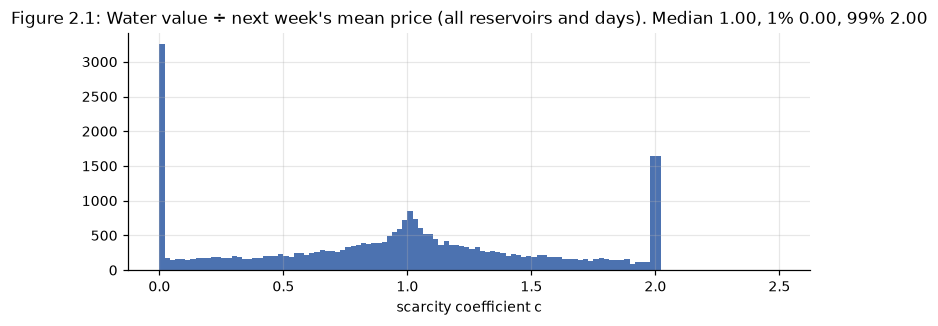

17 water-value columns, 9 distinct series


In [3]:
# Figure 2.1: the water values are synthetic: water value ≈ c × next week's mean price, with c in [0, 2]
wv = data.water_value.loc["2015-01-01":"2024-12-24"]
next_week_price = data.price.rolling(168).mean().shift(-168).resample("D").first().reindex(wv.index)
unique_series = wv.T.drop_duplicates().T  # the 17 columns are only 9 distinct series
ratio = unique_series.div(next_week_price, axis=0).stack()
ratio = ratio[np.isfinite(ratio) & (next_week_price.abs().reindex(ratio.index, level=0) > 5)]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(ratio.clip(-0.5, 2.5), bins=120, color="#4C72B0")
ax.set_title(f"Figure 2.1: Water value ÷ next week's mean price (all reservoirs and days). "
             f"Median {ratio.median():.2f}, 1% {ratio.quantile(.01):.2f}, 99% {ratio.quantile(.99):.2f}")
ax.set_xlabel("scarcity coefficient c")
show_figure("2.1")
print(f"{wv.shape[1]} water-value columns, {unique_series.shape[1]} distinct series")

- **Overlapping cases are solved independently.** A new case starts every day and covers 7 days, so
  neighbouring cases share 6 of 7 days. They nevertheless disagree on about 12% of the shared hours
  (Figure 2.2). The disagreement is spread over the whole week (86.6–88.3% agreement) with a daily
  rhythm, and it is slightly larger near the case boundaries: at the start of the newer case and at the end
  of the older one. It is much larger for Tokke and Vinje (82–85% agreement) than for the small plants
  (94–96%). Possible explanation: each case has its own start state and its own end-of-week valuation, and
  when two schedules are almost equally profitable the optimiser can pick either. Tokke and Vinje have
  several identical units, so they have the most near-ties. This sets a natural limit on how well any model can do, and it is
  also why a random train/test split would leak (§3).

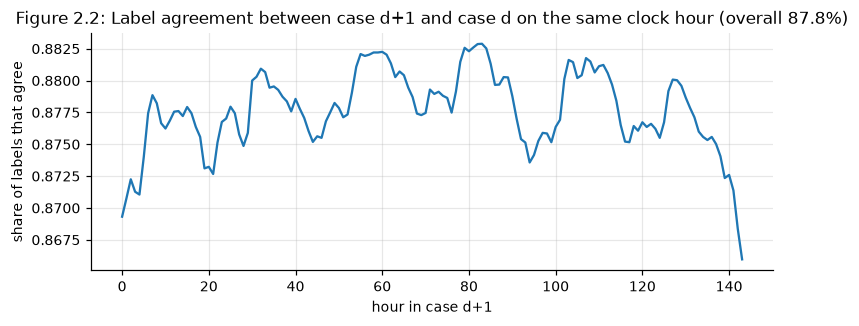

,Hogga_G1,Tokke_G1,Tokke_G2,Tokke_G3,Tokke_G4,Lio_G1,Byrte_G1,Vinje_G1,Vinje_G2,Vinje_G3,Haukeli_G1,Songa_G1,Kjela_G1,Vesle Kjela_G1
agreement,0.843,0.849,0.818,0.827,0.821,0.951,0.964,0.826,0.82,0.835,0.875,0.955,0.943,0.961


In [4]:
# Figure 2.2: neighbouring cases are solved independently: agreement on the shared hours
Y = data.Y  # (case, unit, hour)
consecutive = (data.starts.diff().dt.days == 1).to_numpy()[1: data.n_train]
a = Y[:-1][consecutive][:, :, 24:]    # case d, hours 24–167
b = Y[1:][consecutive][:, :, :144]    # case d+1, hours 0–143 (the same clock hours)
agree_by_hour = (a == b).mean(axis=(0, 1))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(np.arange(144), agree_by_hour)
ax.set_title(f"Figure 2.2: Label agreement between case d+1 and case d on the same clock hour (overall {(a == b).mean():.1%})")
ax.set_xlabel("hour in case d+1"); ax.set_ylabel("share of labels that agree")
show_figure("2.2")
per_unit = pd.Series((a == b).mean(axis=(0, 2)), index=data.units).round(3)
per_unit.to_frame("agreement").T

- **Optimiser run time.** Some cases took much longer to solve (a cluster near ≈ 1000 s that looks
  like a time limit). These labels may be less optimal, which we come back to in §7 and §9.

**2.3 Is the data intuitive? (check if the data is intuitive).**
- **The decisions make economic sense, but only once price and water value are read together
  (Figure 2.3).** "Price" here is always the hourly *electricity* price, and the water value is the value of the
  water in the unit's source reservoir at start + 7 days, in the same unit (EUR/MWh). Each panel will be explained
  in turn:
  - *(a) Over the years.* The water value moves up and down with the price level, because it is defined from
    the price (§2.2). The share of hours ON does not follow the price; it follows which of the two lines is on top.
    In 2020 prices were close to zero (1–20 EUR/MWh, a very wet year), yet units were ON 60–80% of the time in most
    months, because the water value was even lower: the reservoirs were full and the water had to be used. In the
    two 2020 months where the water value was above the price (April, August) the ON rate fell to 21% and 36%. In
    2022 prices were record high (120–450 EUR/MWh), yet units were ON only 9–44% of the time from January to
    September, because the water value was higher still (a dry year, so water was saved for later).
  - *(b) One typical week.* For a single unit, the grey ON blocks line up with the hours where the price
    line is above the water-value line. This is the rule "produce when the price is above the value of the water"
    from §2.1 made visible. The hours where they disagree lie close to the line, where running or not makes
    little difference to the profit, and some of them are explained by start costs: near the end of the week the
    unit stays on for hours slightly below the line instead of stopping and restarting. The week is the median case
    (not the best one), so the reader sees how well the simple rule typically works (86% of hours); the remaining
    14% is what the model has to learn from start costs, the cascade and the other units.
  - *(c) and (d) Over all cases.* Plotting the ON rate against price alone gives a flat or even falling curve:
    above about 80 EUR/MWh units are *less* often on, because those high prices are mostly 2022, where the water
    value was even higher. Plotting it against price minus water value gives a clean S-curve that crosses 50%
    at zero. This sets up the key finding of §2.5.

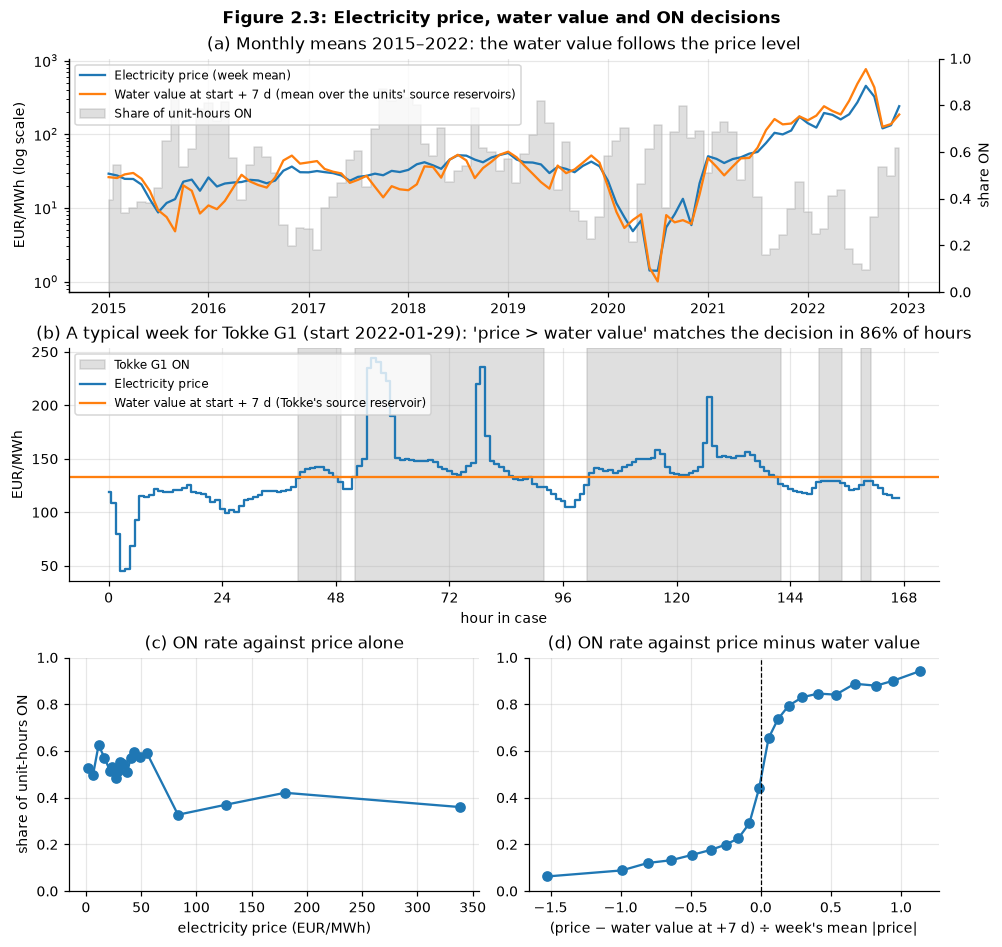

In [5]:
# Figure 2.3: electricity price, water value and ON decisions together
n = data.n_train
price = week_prices(data)[:n]          # (case, hour), EUR/MWh
wv_end = upstream_wv(data, 7)[:n]      # (case, unit): water value of the unit's source reservoir at start + 7 days
on = data.Y[:n]                        # (case, unit, hour)
axd = plt.figure(figsize=(9, 8.5), layout="constrained").subplot_mosaic("AA;BB;CD")

# (a) Over the years: monthly means over all cases and units
month = data.starts[:n].dt.tz_localize(None).dt.to_period("M").to_numpy()
monthly = pd.DataFrame({"price": price.mean(axis=1), "wv": wv_end.mean(axis=1),
                        "on": on.mean(axis=(1, 2))}).groupby(month).mean()
ax, t = axd["A"], monthly.index.to_timestamp()
ax.plot(t, monthly["price"], label="Electricity price (week mean)")
ax.plot(t, monthly["wv"], label="Water value at start + 7 d (mean over the units' source reservoirs)")
ax.set_yscale("log"); ax.set_ylabel("EUR/MWh (log scale)")
ax2 = ax.twinx()
ax2.fill_between(t, monthly["on"], step="mid", color="grey", alpha=0.25, label="Share of unit-hours ON")
ax2.set_ylim(0, 1); ax2.set_ylabel("share ON"); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.legend(*[a + b for a, b in zip(ax.get_legend_handles_labels(), ax2.get_legend_handles_labels())], loc="upper left", fontsize=8)
ax.set_title("(a) Monthly means 2015–2022: the water value follows the price level")

# (b) One typical week for one unit: among weeks where Tokke G1 both runs and stops, the one with median
# agreement between the decision and 'price > water value' (typical, not the best example)
u = data.units.index("Tokke_G1")
above = price > wv_end[:, u:u + 1]
weeks = np.where((on[:, u].mean(1) > 0.3) & (on[:, u].mean(1) < 0.7) & (above.mean(1) > 0.3) & (above.mean(1) < 0.7))[0]
agree = (above[weeks] == on[weeks, u]).mean(axis=1)
c = weeks[np.argsort(agree)[len(weeks) // 2]]
ax, hours = axd["B"], np.arange(HOURS)
ax.fill_between(hours, 0, 1, where=on[c, u] == 1, step="mid", color="grey", alpha=0.25,
                transform=ax.get_xaxis_transform(), label="Tokke G1 ON")
ax.step(hours, price[c], where="mid", label="Electricity price")
ax.axhline(wv_end[c, u], color="C1", label="Water value at start + 7 d (Tokke's source reservoir)")
ax.set_xticks(range(0, HOURS + 1, 24)); ax.set_xlabel("hour in case"); ax.set_ylabel("EUR/MWh")
ax.legend(loc="upper left", fontsize=8)
ax.set_title(f"(b) A typical week for Tokke G1 (start {data.starts[c]:%Y-%m-%d}): "
             f"'price > water value' matches the decision in {(above[c] == on[c, u]).mean():.0%} of hours")

# (c, d) ON rate in 20 quantile bins, 600 random training cases, all units
rng = np.random.default_rng(0)
sample = rng.choice(n, 600, replace=False)
prices = price[sample][:, None, :]                                   # (case, 1, hour)
level = np.abs(prices).mean(axis=2, keepdims=True) + 1
wv_end_s, wv_start_s = wv_end[sample][:, :, None], upstream_wv(data, 0)[sample][:, :, None]
wv_down_s = downstream_wv(data, 7)[sample][:, :, None]
y_sample = on[sample]
candidates = {  # also used in Table 2.2
    "Raw price": np.broadcast_to(prices, y_sample.shape),
    "Price − upstream water value at case start": (prices - wv_start_s) / level,
    "Price − upstream water value at start + 7 days": (prices - wv_end_s) / level,
    "Price − (upstream − downstream) water value at +7 d": (prices - (wv_end_s - wv_down_s)) / level,
}
for key, name, xlabel, title in [
        ("C", "Raw price", "electricity price (EUR/MWh)", "(c) ON rate against price alone"),
        ("D", "Price − upstream water value at start + 7 days", "(price − water value at +7 d) ÷ week's mean |price|",
         "(d) ON rate against price minus water value")]:
    v, yv = np.broadcast_to(candidates[name], y_sample.shape).ravel(), y_sample.ravel()
    idx = np.clip(np.digitize(v, np.quantile(v, np.linspace(0, 1, 21))) - 1, 0, 19)
    axd[key].plot([v[idx == i].mean() for i in range(20)], [yv[idx == i].mean() for i in range(20)], "o-")
    axd[key].set_xlabel(xlabel); axd[key].set_title(title); axd[key].set_ylim(0, 1)
axd["C"].set_ylabel("share of unit-hours ON")
axd["D"].axvline(0, color="k", lw=0.8, ls="--")
plt.suptitle("Figure 2.3: Electricity price, water value and ON decisions", fontweight="bold")
show_figure("2.3")

- Units within a plant follow a **strict priority order**: Vinje G2 is almost never on while G1 is off, and
  Tokke G1 always starts first (Table 2.1). This matches how operators use identical units.

In [6]:
# Table 2.1: priority order within the multi-unit plants
u = {name: i for i, name in enumerate(data.units)}
pairs = [("Vinje_G2", "Vinje_G1"), ("Vinje_G3", "Vinje_G2"), ("Tokke_G3", "Tokke_G1"),
         ("Tokke_G4", "Tokke_G3"), ("Tokke_G2", "Tokke_G4"), ("Tokke_G2", "Tokke_G1")]
rows = []
for lower, higher in pairs:
    lo, hi = data.Y[:, u[lower]], data.Y[:, u[higher]]
    rows.append({"unit": lower, "higher-priority unit": higher,
                 "P(unit ON while higher-priority unit OFF)": f"{((lo == 1) & (hi == 0)).mean():.2%}",
                 "ON rate of unit": f"{lo.mean():.2f}"})
show_table(pd.DataFrame(rows), "2.1")

,unit,higher-priority unit,P(unit ON while higher-priority unit OFF),ON rate of unit
0,Vinje_G2,Vinje_G1,0.07%,0.42
1,Vinje_G3,Vinje_G2,0.02%,0.26
2,Tokke_G3,Tokke_G1,0.05%,0.56
3,Tokke_G4,Tokke_G3,0.29%,0.50
4,Tokke_G2,Tokke_G4,1.87%,0.48
5,Tokke_G2,Tokke_G1,0.03%,0.48


- Some reservoir volumes exceed their stated maximum (up to 18% for Bandak) during floods. We
  checked that this is real (it happens on flood days) and kept it, but our LP had to allow it.

**2.4 Individual features (explore individual features).**
- **Target.** The ON rate is about 0.5 overall but varies a lot by unit and year (Figure 2.4; for example
  Haukeli 0.87 in 2015 and 0.14 in 2022). 59% of unit-weeks are constant (all ON or all OFF).

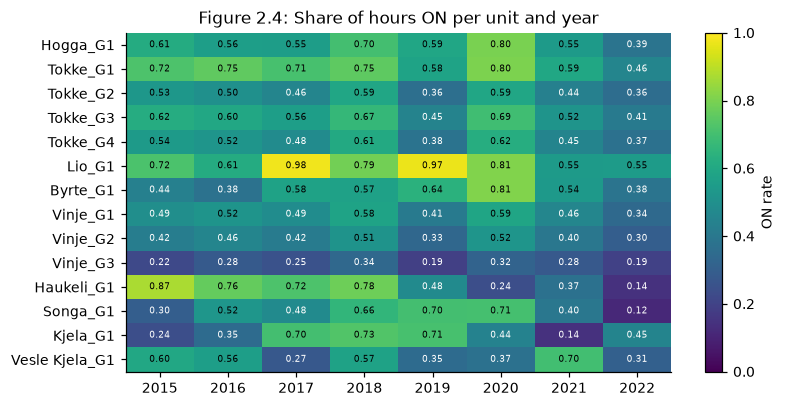

Unit-weeks always ON: 32%, always OFF: 27%


In [7]:
# Figure 2.4: ON rate per unit and year
on_rate = pd.DataFrame(data.Y.mean(axis=2), columns=data.units).groupby(train_years).mean().T
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(on_rate.to_numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(on_rate.shape[1]), on_rate.columns); ax.set_yticks(range(len(on_rate)), on_rate.index)
for i in range(on_rate.shape[0]):
    for j in range(on_rate.shape[1]):
        ax.text(j, i, f"{on_rate.iat[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if on_rate.iat[i, j] < 0.5 else "black")
ax.grid(False); fig.colorbar(im, ax=ax, label="ON rate")
ax.set_title("Figure 2.4: Share of hours ON per unit and year")
show_figure("2.4")
weekly = data.Y.mean(axis=2)
print(f"Unit-weeks always ON: {(weekly == 1).mean():.0%}, always OFF: {(weekly == 0).mean():.0%}")

- **Price** has very different regimes: mean 20–43 EUR/MWh in 2015–2019, 9 in 2020, 211 in the 2022 energy
  crisis, and 79 / 50 in the test years 2023–2024, which also contain about 380 negative-price hours
  (versus about 10 in all training years) (Figure 2.5). This regime shift drove our choice of relative
  price features (§4).

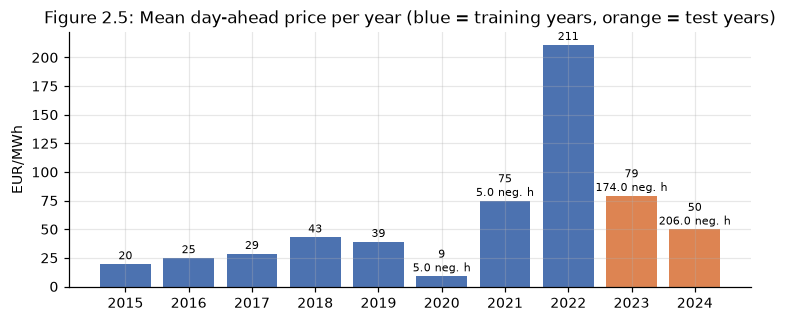

date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mean price (EUR/MWh),20.0,25.0,29.0,43.0,39.0,9.0,75.0,211.0,79.0,50.0
negative-price hours,0.0,0.0,0.0,0.0,0.0,5.0,5.0,0.0,174.0,206.0


In [8]:
# Figure 2.5: price regimes per year, including the test years
price = data.price[: "2024-12-31 23:00"]
by_year = pd.DataFrame({"mean price (EUR/MWh)": price.groupby(price.index.year).mean(),
                        "negative-price hours": (price < 0).groupby(price.index.year).sum()})
fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#4C72B0" if y <= 2022 else "#DD8452" for y in by_year.index]
ax.bar(by_year.index, by_year["mean price (EUR/MWh)"], color=colors)
for y, row in by_year.iterrows():
    ax.text(y, row.iloc[0] + 4, f"{row.iloc[0]:.0f}" + (f"\n{row.iloc[1]} neg. h" if row.iloc[1] > 0 else ""), ha="center", fontsize=7)
ax.set_title("Figure 2.5: Mean day-ahead price per year (blue = training years, orange = test years)")
ax.set_ylabel("EUR/MWh"); ax.set_xticks(by_year.index)
show_figure("2.5")
by_year.T.round(0)

- Inflow, volume and constraints: briefly, with a reference to the EDA notebook.

**2.5 Pairs and groups of features (explore pairs and groups of features).**
- **Price alone predicts nothing (AUC 0.45), but price minus the upstream water value at +7 days
  predicts a lot (0.87)** (Table 2.2, Figure 2.3). This was the single most important EDA finding: the
  signal is in the *relationship* between two inputs, not in either one. Raw price is even slightly
  *inversely* related to running (Figure 2.3c). Explanation: periods of high prices (2022)
  are also periods of high water values (Figure 2.3a), so a high price does not mean the water is worth using.
  In contrast, the ON rate rises steeply as soon as the price passes the water value (Figure 2.3d). This is
  exactly the economic rule from §2.1.

In [9]:
# Table 2.2: each candidate as a single rule, ranked over all units together
table_24 = pd.Series({k: roc_auc_score(y_sample.ravel(), np.broadcast_to(v, y_sample.shape).ravel()) for k, v in candidates.items()},
                     name="AUC as a single rule (all units pooled)").round(3)
show_table(table_24.to_frame(), "2.2")

,AUC as a single rule (all units pooled)
Raw price,0.454
Price − upstream water value at case start,0.748
Price − upstream water value at start + 7 days,0.872
Price − (upstream − downstream) water value at +7 d,0.620


- **Which water value matters.** The start-day water value gives only 0.75, and subtracting the downstream
  reservoir's value gives 0.62 (Table 2.2).
  - *Start day vs +7 days.* SHOP values the water left at the end of the week, so the end-of-week (+7 d)
    value is the relevant one; the start-day value is only a rough proxy for it.
  - *Why the "net" rule was worth testing.* Water a plant uses is not lost: it flows into the downstream
    reservoir, where the next plants can use it again. The textbook cost of using it is therefore
    upstream value − downstream value, which gives the rule "run when price > upstream − downstream water value".
    This tests whether SHOP thinks in net terms or simply compares the price with the value of the water it uses.
  - *Why it works worse (Table 2.3).* The downstream value is not small: the net water value is typically
    about 0.6 × the week's price, while the upstream value alone is about 1.0 × the price. Subtracting it makes
    the water look too cheap, so the net rule says "run" in 84% of unit-hours although units are ON only 52% of
    the time, and it barely separates ON from OFF (56% vs 27% ON). The upstream-only rule says "run" in 52% of
    unit-hours and separates them well (83% vs 18% ON). SHOP's decisions switch where the price crosses the
    upstream value alone (Figure 2.3d).
  - *Possible explanation.* The water values are synthetic (c × next week's price per reservoir, §2.2). Each one
    already acts as "the price at which water in this reservoir is worth using", and they are probably not built
    to be subtracted along the cascade. (Hogga and Lio have no downstream water value, so for them the two rules
    are identical.)

In [10]:
# Table 2.3: the upstream-only rule vs the net (upstream − downstream) rule as simple ON/OFF classifiers
n = data.n_train
price_h = week_prices(data)[:n, None, :]
up, down = upstream_wv(data, 7)[:n, :, None], downstream_wv(data, 7)[:n, :, None]
y_all = data.Y[:n].astype(bool)
rows = {}
for name, says_run in [("Price > upstream water value at +7 d", price_h > up),
                       ("Price > (upstream − downstream) water value at +7 d", price_h > up - down)]:
    rows[name] = {"Share of unit-hours where the rule says 'run'": says_run.mean(),
                  "Share ON when the rule says 'run'": y_all[says_run].mean(),
                  "Share ON when the rule says 'stop'": y_all[~says_run].mean()}
rows["(All unit-hours)"] = {"Share of unit-hours where the rule says 'run'": np.nan,
                            "Share ON when the rule says 'run'": y_all.mean(), "Share ON when the rule says 'stop'": np.nan}
show_table(pd.DataFrame(rows).T.map(lambda x: "" if np.isnan(x) else f"{x:.0%}"), "2.3", columns='p{4.6cm}p{2.8cm}p{2.8cm}p{2.8cm}')

,Share of unit-hours where the rule says 'run',Share ON when the rule says 'run',Share ON when the rule says 'stop'
Price > upstream water value at +7 d,52%,83%,18%
Price > (upstream − downstream) water value at +7 d,84%,56%,27%
(All unit-hours),,52%,


- Tokke and Vinje decisions are strongly correlated (0.6–0.8), which motivated the coupling features.
- The reservoir fill of a unit's *own* source reservoir is strongly related to its ON rate (Songa: on 19% of
  the time in the emptiest weeks versus 93% in the fullest), while system-wide fill and inflow are weak.
- Train and test distributions differ mainly in price level (adversarial check in the EDA notebook).

**2.6 Cleaning (clean up features).** No missing values, gaps or duplicated timestamps in 2015–2024.
We removed the 8 duplicated water-value columns, dropped the constant (placeholder) volumes of
Hyljelihyl and Vatjern, kept the outliers because they are real (floods, price spikes), and aligned
everything to UTC (Table 2.4).

In [11]:
# Table 2.4: cleaning summary
volume = data.volume.loc["2015-01-01":"2024-12-31"]
rows = [
    ("Missing values in input tables", int(sum(t.loc["2015":"2024"].isna().sum().sum() for t in [data.inflow, data.volume, data.water_value]) + data.price["2015":"2024"].isna().sum()), "none to handle"),
    ("Water-value columns that duplicate another column", wv.shape[1] - unique_series.shape[1], "removed (9 distinct series kept)"),
    ("Reservoirs with constant volume (placeholders)", ", ".join(c for c in volume if volume[c].nunique() == 1), "not used as features or LP start states"),
    ("Reservoirs whose volume exceeds max_vol on some days", int(sum((volume[r] > data.max_vol[r]).any() for r in volume if r in data.max_vol)), "kept (real floods); the LP allows it"),
    ("Training cases", data.n_train, "one per day, 2015-01-01 to 2022-12-31"),
]
show_table(pd.DataFrame(rows, columns=["Check", "Result", "Action"]), "2.4", columns='p{4.2cm}p{3cm}p{4.6cm}')

,Check,Result,Action
0,Missing values in input tables,0,none to handle
1,Water-value columns that duplicate another column,8,removed (9 distinct series kept)
2,Reservoirs with constant volume (placeholders),"Hyljelihyl, Vatjern",not used as features or LP start states
3,Reservoirs whose volume exceeds max_vol on some days,14,kept (real floods); the LP allows it
4,Training cases,2922,"one per day, 2015-01-01 to 2022-12-31"


**2.7 Key findings and what they meant for modelling.** We will finish with a short list
that links each finding to a modelling decision, e.g.: "price − water value at +7 d is the core
signal → all margin features use it", "regime shift → relative price features", "overlapping cases →
year-based validation with an embargo", "priority order and coupling → plant-level features".

## 3. Validation strategy

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

This short section explains *how we decided whether a change was an improvement*. It comes before
the features and models because every result in the report depends on it.

- **Why not a random split.** Neighbouring cases share 6 of 7 days and agree on about 88% of their shared
  labels (Figure 2.2). If one case is in training and its neighbour in validation, the model has
  effectively seen most of the answer. A random K-fold would therefore give a far too optimistic score.
  SINTEF's own paper used a random 80/20 split, so its numbers are not comparable to ours.
- **Leave-one-year-out with an embargo.** We validate on one whole year at a time and train on the other
  years. We also remove every training case that starts within 7 days of the validation year, on both
  sides, because a case that starts on 28 December contains the decisions for the first days of
  January (Table 3.1).

In [12]:
# Table 3.1: the four folds and the locked holdout
rows = []
for name, year in {**cv.FOLDS, "Holdout": cv.HOLDOUT_YEAR}.items():
    train_idx, val_idx = cv.split(data, year)
    rows.append({"fold": name, "validation year": year, "validation cases": len(val_idx), "training cases": len(train_idx),
                 "removed by the 7-day embargo": data.n_train - len(val_idx) - len(train_idx),
                 "mean price (EUR/MWh)": round(data.price[str(year)].mean())})
show_table(pd.DataFrame(rows), "3.1")

,fold,validation year,validation cases,training cases,removed by the 7-day embargo,mean price (EUR/MWh)
0,A,2020,366,2544,12,9
1,B,2021,365,2545,12,75
2,C,2022,365,2551,6,211
3,D,2019,365,2545,12,39
4,Holdout,2018,365,2545,12,43


- **Four folds.** A = 2020 (very low prices), B = 2021 (rising prices), C = 2022 (crisis prices), D = 2019 (normal
  prices). We added 2019 because the other three are all unusual years and none resembles the test
  period; without a normal year the average could be steered towards changes that only help in
  extreme years. The score of a configuration is the mean AUC over the four folds.
- **A locked holdout year (2018).** We never looked at 2018 while choosing features or settings, and scored it
  exactly once for the two final models, as an honest check that we had not overfitted the four folds.
- **The acceptance rule.** We measured that changing only the random seed moves a fold by up to 0.0017 and the
  mean by up to 0.0008. A change was therefore accepted only if the mean improved by at least 0.001,
  at least 3 of 4 folds did not get worse, and no fold dropped by more than 0.002. Among equal scores we chose the
  simpler model. For borderline cases we ran a second seed. We will explain why this matters: with
  dozens of experiments, some changes would look better by pure luck, and a fixed rule protects
  against fooling ourselves.
- **The public leaderboard** was used only as a sanity check after large steps (about one upload per step), never to choose
  between small variants, because it is a small sample of 2023–2024 and the final grade uses the private part.
- **Final models** are retrained on all 2015–2022 cases with the chosen settings. The fold models are only used to
  score settings.

## 4. Feature engineering

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

This is the core of the report. We will tell it as a story in stages, because each stage was
motivated by what the previous one could not do. For every stage we state the idea, the physical or
economic reason behind it, the measured effect (Figure 4.1) and our best explanation of
*why* it worked or did not.

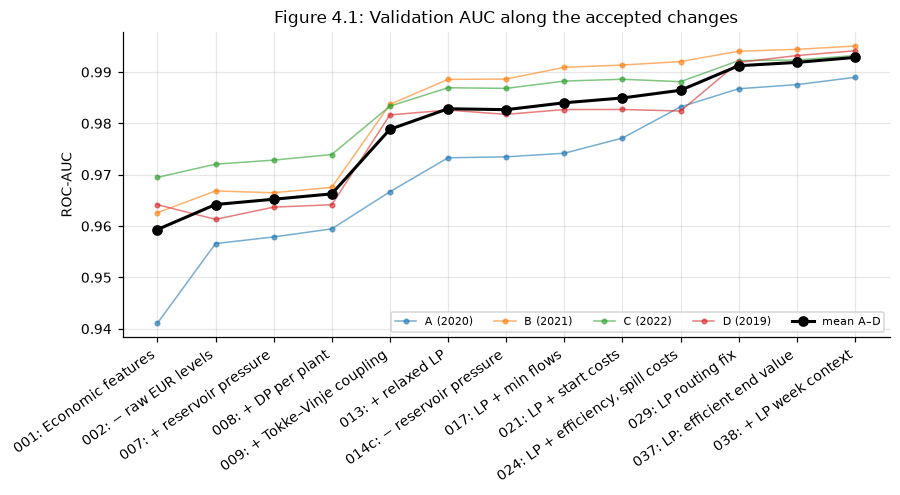

,A,B,C,D,mean,gain
001: Economic features,0.9411,0.9626,0.9695,0.9642,0.9593,NaN
002: − raw EUR levels,0.9566,0.9669,0.9721,0.9613,0.9642,0.0049
007: + reservoir pressure,0.9579,0.9665,0.9729,0.9637,0.9652,0.0010
008: + DP per plant,0.9595,0.9676,0.9739,0.9642,0.9663,0.0010
009: + Tokke–Vinje coupling,0.9667,0.9837,0.9834,0.9817,0.9789,0.0126
013: + relaxed LP,0.9733,0.9886,0.9870,0.9826,0.9829,0.0040
014c: − reservoir pressure,0.9735,0.9886,0.9868,0.9818,0.9827,-0.0002
017: LP + min flows,0.9742,0.9909,0.9883,0.9827,0.9840,0.0013
021: LP + start costs,0.9772,0.9914,0.9886,0.9827,0.9850,0.0009
"024: LP + efficiency, spill costs",0.9832,0.9921,0.9881,0.9824,0.9865,0.0015


In [13]:
# Experiment log (machine-readable) and the journal's decisions
# keep="last": for exp 029 that is the deterministic re-run that was submitted
results = pd.read_csv(EXP / "results.csv")
cv_rows = results.dropna(subset=["mean"]).drop_duplicates("name", keep="last").set_index("name")

kept = [  # the path of accepted changes, in order
    ("exp_001_baseline_v2", "Economic features"),
    ("exp_002_no_raw_eur", "− raw EUR levels"),
    ("exp_007_hydro_pressure", "+ reservoir pressure"),
    ("exp_008_relaxed_dp", "+ DP per plant"),
    ("exp_009_tokke_vinje", "+ Tokke–Vinje coupling"),
    ("exp_013_relaxed_lp", "+ relaxed LP"),
    ("exp_014c_without_hydro_pressure", "− reservoir pressure"),
    ("exp_017_lp_minflow", "LP + min flows"),
    ("exp_021_lp_commitment", "LP + start costs"),
    ("exp_024_lp_shop", "LP + efficiency, spill costs"),
    ("exp_029_main_river", "LP routing fix"),
    ("exp_037_terminal_efficiency", "LP: efficient end value"),  # +0.0007, fails the rule alone; kept as part of 038
    ("exp_038_dispatch_context", "+ LP week context"),
]
progress = cv_rows.loc[[k for k, _ in kept], ["A", "B", "C", "D", "mean"]]
progress.index = [f"{k.split('_')[1]}: {lbl}" for k, lbl in kept]

fig, ax = plt.subplots(figsize=(9, 3.6))
for fold, year in cv.FOLDS.items():
    ax.plot(range(len(progress)), progress[fold], "o-", lw=1, ms=3, alpha=0.6, label=f"{fold} ({year})")
ax.plot(range(len(progress)), progress["mean"], "o-", color="black", lw=2, label="mean A–D")
ax.set_xticks(range(len(progress)), progress.index, rotation=35, ha="right")
ax.set_ylabel("ROC-AUC"); ax.legend(ncol=5, fontsize=7, loc="lower right")
ax.set_title("Figure 4.1: Validation AUC along the accepted changes")
show_figure("4.1")
progress.assign(gain=progress["mean"].diff()).round(4)

**4.1 Principles we followed.**
- *Only use what SHOP knew.* Every feature is computed from the case's own inputs: prices, inflows and
  constraints inside the week, the volume at the start, and the water values at the start and at +7 days.
  Reservoir volumes after the start day are observed outcomes and would leak information, so they are never used.
  Neither is the optimiser's calculation time.
- *Relative, not absolute, prices.* Because the price level changes by a factor of 20 between years (Figure 2.5),
  features are expressed relative to the week's price level (ranks, z-scores, differences divided by the
  level). A tree that learns "on if price > 100 EUR" in 2022 would fail in 2020 and in the test years.
- *Feature extraction over feature selection.* Most of our work is feature *extraction* (building new
  features from physics). Feature *selection* was done by group: a group was added only if it passed the
  acceptance rule, and from time to time we removed one group at a time (ablation) to check that it was
  still needed.

**4.2 Stage 1: economic features (exp 001, mean AUC 0.9593).** Our first harness model used price shape
(rank and z-score within the week), calendar, the price − water value margins, scarcity coefficients
(how full the reservoir is, according to the water value), reservoir fill and inflow, and unit
properties. We will explain each family in one or two sentences using the feature table.

**4.3 Removing raw EUR levels (exp 002, +0.005; 2020 +0.016).** Removing the six features in raw EUR (the price
itself, the week's mean price and the raw water values) *improved* the score, most clearly for 2020 when prices
were extremely low. Explanation: the trees had learned thresholds in EUR that only hold in the price
regime they were trained on. This is a feature-selection result worth highlighting.

**4.4 Rearranging the margin does not help (exps 005, 006).** Margins in neighbouring hours, rolling means
and the length of profitable blocks gave nothing beyond noise. Explanation: a tree model can already
combine the existing margin and price-shape features. *Lesson we will state explicitly:* gains come
from *new information*, not from re-expressing existing information. *Correction found later (§4.10):*
the same kind of summary over the week *did* help when it was computed from the LP's outputs instead of
the simple margin. So the lesson must be stated more carefully: rearranging a weak signal does not help,
but summarising a strong one can.

**4.5 Reservoir pressure (exp 007, kept; later removed in exp 014c).** Week inflow divided by the free space in the
reservoir: a nearly full reservoir with high inflow must produce or spill water, whatever the price. It
helped 2019, but once the LP was added it became redundant (the LP knows the reservoir limits) and the
ablation removed it. Good example of a feature that was useful at one stage and redundant at the next.

**4.6 A dynamic programme per plant (exp 008, +0.001, all folds up).** We will explain in plain words: for each
plant, we search all on/off paths over the week and pick the one with the highest profit (price −
water value, times production) minus start costs. This is cheap (milliseconds per case) and
gives a schedule that already has realistic blocks instead of hour-by-hour switching. The most useful output was
the *regret*: how much profit would be lost by doing the opposite in that hour. It acts as a confidence
measure. Why the gain was modest: the DP treats each plant separately and ignores reservoir limits.

**4.7 Tokke–Vinje coupling (exp 009, +0.013, the largest single jump before the LP).** Each Tokke unit gets
Vinje's DP schedule and margin, and the other way round. Explanation: Vinje releases into the tiny Vinjevatn,
which Tokke must empty, so when Vinje G1 runs, Tokke G1 runs 99.5% of the time (otherwise 37%). The
partner features are weak alone but strong together with the unit's own features, which is exactly the kind of
interaction trees are good at. Tokke G2–G4 improved by 0.02–0.08.

**4.8 The relaxed LP of the whole watercourse (exp 013, +0.004; the most important feature).** We will
explain carefully, because this is the key idea:
- *What it is.* We wrote a simplified version of SHOP's optimisation problem as a linear program. For each hour it
  decides how much water each plant uses, how much is spilled, and how full each reservoir is. Water balance
  equations link the reservoirs along the topology file's connections. The objective is to maximise income from selling
  power at the known prices plus the value of the water left at the end of the week (at the +7 d water values).
- *What "relaxed" means.* In SHOP a unit is either on or off (an integer decision), which makes the problem
  slow to solve. We allow "partly on" values between 0 and 1, which turns it into an LP that solves in a fraction of a second.
  All 3647 cases take about 7 minutes on one CPU core.
- *What it gives us.* For every plant and hour, the LP's production and committed units, and the
  *shadow price* of water in each reservoir: the effective hourly value of one more unit of water,
  which accounts for reservoirs filling up or running empty. These are better water values than the static
  daily ones.
- *Why it works so well.* The labels *are* the solution of almost the same optimisation problem. The LP
  reproduces the economics and the physical constraints together (limits, coupling, start costs). The GBDT then
  only has to learn the systematic differences between the relaxed and the real integer solution
  (for example, the LP tends to commit too many units). SINTEF's paper supports this: their relaxed solution
  alone scored F1 ≈ 0.97, and neural networks added only ≈ 0.004 on top.
- *A failure that taught us something.* Valuing leftover water "all the way to the sea" at each reservoir's own water
  value made the LP much worse (AUC ≈ 0.70). Explanation: the synthetic water values are not consistent
  with each other across reservoirs, so long chains of differences amplify their noise. Valuing each plant's
  water at its own upstream water value (our "path" valuation) works.

**4.9 Making the LP more like SHOP (exps 017, 021, 024, 029; 0.9840 → 0.9912).** We improved the LP step by step and
measured each step separately:
- *Minimum river flows (017):* Lio improved by 0.02–0.07, because a minimum-flow requirement on its river forces it to run.
- *Relaxed unit commitment (021):* start/stop costs and minimum production inside the LP, which improves timing.
- *Efficiency curves and SHOP's spill costs (024):* mostly helped 2020, when water values were near zero and the old
  LP could "dump" water for free.
- *The routing bug fix (029, +0.0047, all folds up):* this is our case study, explained in plain words. The LP
  picked the *first* river leaving each reservoir. For Hyljelihyl that is a bypass that skips the Vinje plant,
  while the topology file marks another river (via Totak to Vinje) as the main one. Water left in Hyljelihyl, and in
  every lake above it, was therefore valued too low, which made running Kjela look too attractive and distorted the
  water prices along the Totak–Vinje–Tokke chain. Fixing it improved Haukeli from 0.923 to 0.974 and Kjela from
  0.977 to 0.989. *Lesson:* checking that the model's physics is right was worth more than any tuning.
- We will also mention LP variants that were tested and dropped (head iterations, integer units, alternative
  valuations), with one line each.

**4.10 Efficient end-of-week valuation and the LP over the whole week (exps 037, 038; 0.9912 → 0.9929).**
A late improvement round, two changes on top of exp 029:
- *Valuing leftover water at the best efficiency (037, +0.0007, all four years up).* The LP turns the
  water left at the end of the week into money via the end water value (EUR/MWh), so it must convert
  m³ to MWh. Until now it used the plant's average efficiency at full load; 037 uses the efficiency of
  the first, most efficient production segment instead (`relaxed_lp_best`, features `lpb_*`). This is
  closer to how the water would actually be used later, and it values saved water higher, so the LP
  holds back more water. Only the end-of-week value changes; production inside the week is modelled as
  before. LP check on every sixth training case: LP unit on alone 0.9447 → 0.9597, LP margin alone
  0.9739 → 0.9770. The model gain (+0.0007) was below the acceptance threshold on its own.
- *The LP over the whole week (038, +0.0016 vs 029, all four years up; 56 features).* Each training row
  sees only one hour, but whether a unit runs in that hour depends on the rest of the week. 17 new
  features (`lp_dispatch_context`, family "LP week context" in Table A.1) give the hour that context,
  all computed from the LP's outputs: 6 h and 24 h rolling means of the LP's unit on and margin, the
  week's mean, minimum and maximum of both, the share of hours with a positive LP margin, Tokke's and
  Vinje's LP production and margin for every unit, and a *start-cost regret on the LP margin* (the DP of
  §4.6, run on the LP's margin instead of the simple price − water value margin).
- *Why this worked when the rolling means of exp 005 did not.* The LP margin already includes the
  reservoir limits, the coupling and the hourly water values, so its weekly profile carries much more
  information than the simple margin's. Our best guess is that the weekly view (is this hour one of the
  few good ones, or is the unit on all week?) is hard for a tree to rebuild from one hour's values.
- *Protocol, stated openly.* 037 failed the acceptance rule alone but was kept and combined with the
  context features in 038; the context features were never tested without 037. 038's gain (+0.0016) is
  twice the seed noise (0.0008) and every fold improves. A larger fit on the same features (exp 039,
  60% rows, 2200 trees) gave only +0.0002 more, below the noise, so it was not selected (§6).
- *The gain is not specific to LightGBM.* The XGBoost twin (exp 041: the same 56 features, settings as
  exp 030) gains +0.0017 over its own reference 030, and all four years improve. So the gain comes from the
  new features, not from one model type.
- *Tried and dropped (one line each):* 16 production segments instead of 4 (no clear LP gain), a separate
  model for the unit's weekly on-share (+0.00005), and smoothing the predicted probabilities over the
  hours (median filter, probability or logit smoothing: no gain).

**4.11 What did not help once the LP was in (exps 019, 025–027, 031).** A water budget, forward-looking margins,
head proxies, the real storage lake behind Haukeli, an unclipped LP units-on gap and the joint fill of lakes
joined by tunnels all gave ± 0.0002. Common explanation: the LP already computes this information.
Interesting detail: the water budget *did* help the model without the LP (+0.001), which confirms the explanation.

**4.12 Summary of feature selection.** The table of experiments (Table 4.1) shows every change, its effect and the
decision. The ablation (014a–c) showed that the DP (−0.0011 without it) and the coupling (−0.0071) are still needed
next to the LP. Some redundant features remain (e.g. two versions of the net margin) because tree models tolerate
them and removing them did not change the score. Both final models, exp 038 (LightGBM) and exp 041 (XGBoost),
use the same 56 features in 12 families (Table A.1). Figure 7.1 shows how much each feature family contributes
to the LightGBM model.

In [14]:
# Table B.1 (appendix): every experiment, its change and the decision (from experiments/journal.md)
journal_lines = [l for l in (EXP / "journal.md").read_text(encoding="utf-8").splitlines() if l.startswith("| 2026")]
journal = pd.DataFrame([[c.strip() for c in l.strip("|").split("|")] for l in journal_lines],
                       columns=["date", "experiment", "change", "A", "B", "C", "D", "2018", "mean", "compared with", "rule", "public LB", "decision"])
journal = journal[journal["mean"] != "—"].drop_duplicates("experiment", keep="last")  # 029: the submitted re-run
full_decision = journal["decision"]
journal["decision"] = journal["decision"].str.replace("**", "", regex=False).str.split(r"\.(?:\s|$)", regex=True).str[0]
# The final choice (2026-11-05) was appended to the end of older entries, so the first sentence is out of date
journal.loc[full_decision.str.contains("Not selected"), "decision"] = "Not selected: below the seed noise vs 038/041"
journal.loc[journal["experiment"].isin(["exp_029_main_river", "exp_030_xgb_main_river"]), "decision"] = "Keep; final pick until replaced by 046/047"
journal.loc[journal["experiment"].isin(["exp_038_dispatch_context", "exp_041_xgb_dispatch_context"]), "decision"] = "Replaced by 046/047 (same score without next week's price)"
journal["experiment"] = journal["experiment"].str.removeprefix("exp_")  # shorter names fit the column
show_table(journal[["experiment", "change", "mean", "public LB", "decision"]].reset_index(drop=True), "B.1", columns=r">{\raggedright\arraybackslash}p{0.16\linewidth}>{\raggedright\arraybackslash}p{0.35\linewidth}l"
           r">{\raggedright\arraybackslash}p{0.11\linewidth}>{\raggedright\arraybackslash}p{0.17\linewidth}", long=True)

,experiment,change,mean,public LB,decision
0,001_baseline_v2,"baseline_v2 (31 features, pooled LightGBM) moved into our experiment framework",0.9593,,
1,002_no_raw_eur,"exp 001 without the 6 raw EUR level features (price, price_wkmean, raw water values)",0.9642,,Keep (decided after exps 003/004)
2,003a_seed1_of_001,exp 001 with seed 1 (noise check),0.9601,,Noise reference (not a candidate)
3,003b_seed1_of_002,exp 002 with seed 1 (noise check),0.9646,,Noise reference
4,004_no_raw_price,"exp 001 without raw price levels (price, price_wkmean); raw water values kept",0.9613,,Drop
...,...,...,...,...,...
56,045b_mlp_deep,"exp 044 with a third layer (128-64-32, was 128-64)",0.9874,,Drop
57,045c_mlp_slow_lr,"exp 044 with learning rate 0.0003 and up to 60 epochs (was 0.001, 30)",0.9890,,"Best MLP (passes vs 044, +0.0010, all folds up)"
58,045d_mlp_l2,"exp 044 with 10x stronger L2 regularisation (alpha 0.001, was 0.0001)",0.9884,,Drop
59,046_no_next_week_price,"exp 038 without the two features that use the price of the week after the case (scarcity_end, next_week_price)",0.9929,0.99558,Keep: final model 1


## 5. Models (predictor types)

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

We will compare all predictor types we tried *on the same folds*, from no learning at all to the
final models (Table 5.1), and explain why some work better than others.

In [15]:
# Table 5.1: predictor types on the same folds (A–D)
lp, lp_names = load_group("relaxed_lp_best", data)  # the LP of the final models (exp 046/047)
lp_on, lp_margin = lp[..., lp_names.index("lpb_unit_on")], lp[..., lp_names.index("lpb_margin")]
rule = (week_prices(data)[:, None, :] - upstream_wv(data, 7)[:, :, None])

def fold_scores(pred_for):
    out = {}
    for fold, year in cv.FOLDS.items():
        _, val_idx = cv.split(data, year)
        out[f"{fold} ({year})"] = cv.score(data, val_idx, pred_for(fold, val_idx))
    out["mean"] = np.mean(list(out.values()))
    return out

saved = lambda name: (lambda fold, idx: np.load(EXP / name / f"pred_{fold}.npy"))
table_51 = pd.DataFrame({
    "Rule: price − upstream water value (+7 d)": fold_scores(lambda f, idx: rule[idx]),
    "Relaxed LP alone: unit on": fold_scores(lambda f, idx: lp_on[idx].astype(float)),
    "Relaxed LP alone: marginal profit": fold_scores(lambda f, idx: lp_margin[idx].astype(float)),
    "Logistic regression (exp 042)": fold_scores(saved("exp_042_logistic_final")),
    "Random forest (exp 043)": fold_scores(saved("exp_043_random_forest_final")),
    "Neural network, MLP (exp 044)": fold_scores(saved("exp_044_mlp_final")),
    "Neural network, MLP tuned (exp 045c)": fold_scores(saved("exp_045c_mlp_slow_lr")),
    "LightGBM without LP features (exp 009)": fold_scores(saved("exp_009_tokke_vinje")),
    "XGBoost without LP features (exp 012)": fold_scores(saved("exp_012_xgboost")),
    "LightGBM, one model per unit (exp 028f)": fold_scores(saved("exp_028f_per_unit")),
    "LightGBM, with next week's price (exp 038)": fold_scores(saved("exp_038_dispatch_context")),
    "LightGBM, pooled (exp 046, final 1)": fold_scores(saved("exp_046_no_next_week_price")),
    "XGBoost, pooled (exp 047, final 2)": fold_scores(saved("exp_047_xgb_no_next_week_price")),
    "Blend 50/50 of exp 046 and 047": fold_scores(lambda f, idx: 0.5 * np.load(EXP / "exp_046_no_next_week_price" / f"pred_{f}.npy")
                                                   + 0.5 * np.load(EXP / "exp_047_xgb_no_next_week_price" / f"pred_{f}.npy")),
}).T.round(4)
show_table(table_51, "5.1")

,A (2020),B (2021),C (2022),D (2019),mean
Rule: price − upstream water value (+7 d),0.8559,0.8488,0.9115,0.8629,0.8698
Relaxed LP alone: unit on,0.9510,0.9620,0.9645,0.9573,0.9587
Relaxed LP alone: marginal profit,0.9541,0.9632,0.9617,0.9625,0.9604
Logistic regression (exp 042),0.9771,0.9901,0.9872,0.9889,0.9858
Random forest (exp 043),0.9839,0.9922,0.9903,0.9911,0.9894
"Neural network, MLP (exp 044)",0.9786,0.9916,0.9899,0.9918,0.9880
"Neural network, MLP tuned (exp 045c)",0.9813,0.9922,0.9903,0.9922,0.9890
LightGBM without LP features (exp 009),0.9667,0.9837,0.9834,0.9817,0.9789
XGBoost without LP features (exp 012),0.9650,0.9833,0.9830,0.9806,0.9780
"LightGBM, one model per unit (exp 028f)",0.9808,0.9917,0.9872,0.9804,0.9850


*Note:* exp 028f (one model per unit) uses the LP features of exp 024, the previous LP version; compare it with exp 024 (0.9865), not with exp 029.

**5.1 Rules without learning (baselines).** (a) The single economic rule "price − upstream water value at +7 d"
ranks all unit-hours by one number. (b) The relaxed LP alone, ranking by its fractional "unit on" or by its
marginal profit. Including these shows how much comes from the physics and how much from the machine learning:
the LP alone is already strong, and the GBDT on top closes most of the remaining gap.

**5.2 Gradient-boosted trees: LightGBM (final model 1).** Why this model type: the data is tabular (one row per
case × unit × hour, about 6.9 million rows); trees capture interactions such as "the partner plant runs *and* the
margin is positive" without us specifying them; they are robust to features on different scales and to
redundant features; they handle missing values (the partner features are empty for most units); and they
train in under a minute. With about 2900 cases, tree ensembles are the usual strong choice for tabular data
(Grinsztajn et al., 2022). We use one *pooled* model for all 14 units with the unit ID as a categorical feature.

**5.3 XGBoost (final model 2).** Same features, settings matched to LightGBM (leaf-wise growth, same number of
leaves and trees). It scores the same as LightGBM (0.9910 vs 0.9912), and its test predictions correlate 0.997
with LightGBM's. Explanation: both are gradient-boosted trees, and with these features the information,
not the learning algorithm, sets the limit. We still chose it as the second submission because it is a different
implementation, which gives some insurance on the private leaderboard, and its public score was slightly higher.

**5.4 One model per unit versus one pooled model (exps 010, 028f).** Separate models for each unit were worse
(−0.0016 and −0.0014). Explanations: (1) the economics are shared by all units, so a pooled model learns them from 14×
more data; (2) separate models produce probabilities on separate scales, while micro-AUC ranks all units in
one list, so a common scale helps directly.

**5.5 Blends (exp 020 and LightGBM + XGBoost on the final features).** Averaging LightGBM and XGBoost gave
+0.0000 to +0.0001. Explanation: blending only helps when models make *different* errors, and these two make
nearly the same errors because they see the same features.

**5.6 Integer optimisation (MILP) instead of the LP.** Solving the LP with true on/off decisions is closer to SHOP but
gave *worse* features (units-on AUC 0.911 vs 0.945). Explanation: AUC rewards knowing *how close* a decision is; the
fractional LP value carries that information, a hard 0/1 decision throws it away.

**5.7 Post-processing we tried.** Smoothing predictions over neighbouring hours (worse at every window size, because
the labels switch sharply and the LP timing is precise); enforcing the plant priority order (no effect, the model
already respects it); averaging predictions over overlapping cases (worse, because neighbouring cases are solved
independently and disagree on 12% of hours).

**5.8 Neural networks (not trained).** We will be honest that we did not train a neural network, and explain why: with
about 2900 weeks of data, tree models on tabular features are the safer choice; SINTEF's paper shows that neural
networks on this dataset mainly add a small correction on top of the relaxed LP's solution; and our time went into the LP,
which was where the gains were. A 1D CNN over the LP's hourly outputs would be the natural next model to try.

## 6. Hyperparameters

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

The course requires us to explain how the values written in the short notebooks were chosen. We will go through
them one by one and then show the tuning experiments.

- **Starting point.** The LightGBM settings came from our first baseline: 800 trees, learning rate 0.05, 127 leaves per tree,
  at least 200 rows per leaf, 80% of rows and 80% of features sampled per tree (Table 6.1). These are common, moderately regularised
  values for a large dataset. The minimum of 200 rows per leaf matters because neighbouring hours are almost identical
  rows, so very small leaves would memorise single weeks.

In [16]:
# Table 6.1: the hyperparameters in the short notebooks
cfg_lgbm = yaml.safe_load((ROOT / "configs/exp_046_no_next_week_price.yaml").read_text())["model"]
cfg_xgb = yaml.safe_load((ROOT / "configs/exp_047_xgb_no_next_week_price.yaml").read_text())["model"]
lg, xg = cfg_lgbm["params"], cfg_xgb["params"]
table_61 = pd.DataFrame([
    ("Number of trees", f"n_estimators = {lg['n_estimators']}", f"n_estimators = {xg['n_estimators']}", "How many correction steps the model takes"),
    ("Learning rate", f"learning_rate = {lg['learning_rate']}", f"learning_rate = {xg['learning_rate']}", "How much each tree is allowed to change the prediction"),
    ("Tree size", f"num_leaves = {lg['num_leaves']}", f"max_leaves = {xg['max_leaves']} (leaf-wise, no depth limit)", "How detailed each tree can be"),
    ("Minimum leaf size", f"min_child_samples = {lg['min_child_samples']}", f"min_child_weight = {xg['min_child_weight']} (≈ 200 rows)", "How many rows a leaf must contain"),
    ("Rows per tree", f"subsample = {lg['subsample']}", f"subsample = {xg['subsample']}", "Share of rows each tree is trained on"),
    ("Features per tree", f"colsample_bytree = {lg['colsample_bytree']}", f"colsample_bytree = {xg['colsample_bytree']}", "Share of features each tree may use"),
    ("Training rows", f"{cfg_lgbm['row_share']:.0%} of rows", f"{cfg_xgb['row_share']:.0%} of rows", "Random sample of the training years used per model"),
    ("Random seed", str(cfg_lgbm["seed"]), str(cfg_xgb["seed"]), "Makes the results reproducible"),
], columns=["Setting", "LightGBM (notebook 1)", "XGBoost (notebook 2)", "What it controls"])
show_table(table_61, "6.1", columns=r">{\raggedright\arraybackslash}p{0.16\linewidth}>{\raggedright\arraybackslash}p{0.22\linewidth}>{\raggedright\arraybackslash}p{0.25\linewidth}>{\raggedright\arraybackslash}p{0.27\linewidth}")
table_61

,Setting,LightGBM (notebook 1),XGBoost (notebook 2),What it controls
0,Number of trees,n_estimators = 800,n_estimators = 800,How many correction steps the model takes
1,Learning rate,learning_rate = 0.05,learning_rate = 0.05,How much each tree is allowed to change the prediction
2,Tree size,num_leaves = 127,"max_leaves = 127 (leaf-wise, no depth limit)",How detailed each tree can be
3,Minimum leaf size,min_child_samples = 200,min_child_weight = 50 (≈ 200 rows),How many rows a leaf must contain
4,Rows per tree,subsample = 0.8,subsample = 0.8,Share of rows each tree is trained on
5,Features per tree,colsample_bytree = 0.8,colsample_bytree = 0.8,Share of features each tree may use
6,Training rows,35% of rows,35% of rows,Random sample of the training years used per model
7,Random seed,0,0,Makes the results reproducible


- **Row subsampling (35% of rows).** The full training matrix has about 6.9 million rows, which does not fit comfortably in memory
  on our laptops. Neighbouring hours of the same week carry almost the same information, so a random 35% loses very little. We
  checked this: 60% of rows with 1500 trees (exp 016) gave −0.0001 at three times the training time.
- **Tuning sweep (exps 028a–e).** We varied the number of leaves (31, 255), the minimum leaf size (50, 1000) and feature
  sampling (0.5) (Table 6.2). Every variant was equal or slightly worse (−0.0006 to −0.0000). Our interpretation: the model is limited by its
  features, not by its capacity or regularisation, which is also why our effort went into the features.

In [17]:
# Table 6.2: capacity and tuning experiments (each compared with its reference)
tuning = [  # (experiment, reference, change)
    ("exp_016_capacity", "exp_014c_without_hydro_pressure", "60% of rows, 1500 trees, learning rate 0.03"),
    ("exp_028a_leaves_255", "exp_024_lp_shop", "255 leaves (was 127)"),
    ("exp_028b_leaves_31", "exp_024_lp_shop", "31 leaves (was 127)"),
    ("exp_028c_min_leaf_50", "exp_024_lp_shop", "at least 50 rows per leaf (was 200)"),
    ("exp_028d_min_leaf_1000", "exp_024_lp_shop", "at least 1000 rows per leaf (was 200)"),
    ("exp_028e_colsample_05", "exp_024_lp_shop", "50% of features per tree (was 80%)"),
]
rows = []
for name, ref, change in tuning:
    diff = cv_rows.loc[name, ["A", "B", "C", "D", "mean"]] - cv_rows.loc[ref, ["A", "B", "C", "D", "mean"]]
    rows.append({"Exp": name.split("_")[1], "Change": change, **{f"{k}": f"{v:+.4f}".replace("-", "−") for k, v in diff.items()}})
table_62 = pd.DataFrame(rows).rename(columns={"A": "A (2020)", "B": "B (2021)", "C": "C (2022)", "D": "D (2019)", "mean": "mean"})
show_table(table_62, "6.2", columns=r"l>{\raggedright\arraybackslash}p{0.33\linewidth}lllll")
table_62

,Exp,Change,A (2020),B (2021),C (2022),D (2019),mean
0,016,"60% of rows, 1500 trees, learning rate 0.03",−0.0004,−0.0001,+0.0002,+0.0001,−0.0001
1,028a,255 leaves (was 127),−0.0004,+0.0001,−0.0001,+0.0002,−0.0000
2,028b,31 leaves (was 127),−0.0015,−0.0004,+0.0002,−0.0007,−0.0006
3,028c,at least 50 rows per leaf (was 200),−0.0010,+0.0000,−0.0001,+0.0000,−0.0002
4,028d,at least 1000 rows per leaf (was 200),−0.0005,−0.0002,+0.0001,−0.0003,−0.0002
5,028e,50% of features per tree (was 80%),−0.0010,−0.0001,−0.0001,−0.0002,−0.0003


- **No early stopping.** We used a fixed number of trees, since the score was flat across settings and a fixed number makes the final
  model trained on all years identical in setup to the validated one.
- **XGBoost** settings were translated from LightGBM's (leaf-wise growth with 127 leaves, `min_child_weight` 50 ≈ 200 rows,
  because each row's hessian is at most 0.25) rather than tuned separately.
- **Determinism.** Fixed seed, 4 threads and LightGBM's deterministic mode, so that the short notebooks reproduce our Kaggle files
  exactly (verified: byte-identical output in a fresh environment, about 9 minutes per notebook).
- **LP settings** (efficiency-curve pieces, spill and bypass costs) come from SHOP's topology file, not from tuning.

## 7. Model interpretation

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

We interpret the final LightGBM model in four ways, going from the whole model down to a single week. For this
section we train the final configuration on fold B's training years and explain its predictions for 2021, the
validation year whose price level (75 EUR/MWh) is closest to the test years.

In [18]:
# Train the final LightGBM configuration on fold B's training years (validation year 2021)
cfg = yaml.safe_load((ROOT / "configs/exp_046_no_next_week_price.yaml").read_text())
X, names = build_matrix(cfg["features"], data, cfg["drop_features"])
train_idx, val_idx = cv.split(data, cv.FOLDS["B"])
model = models.fit(cfg["model"], X, data.Y, train_idx, names)
pred_B = models.predict(model, X, val_idx)
print(f"fold B (2021) AUC: {cv.score(data, val_idx, pred_B):.4f}")

  building feature group 'lp_dispatch_context'


fold B (2021) AUC: 0.9952


**7.1 Feature importance (Figure 7.1).** Total gain per feature and per feature family. What to say: the relaxed-LP features
account for about 80% of the total gain, and "LP: unit on" alone for about half. Next come the unit ID, reservoir inflow,
the DP regret and the calendar. Everything we built before the LP still contributes, but much less. This confirms the
story of §4: the model's knowledge comes mainly from the optimisation. Caveat we will mention: gain importance does
not show *direction*, and it favours features that are used for the first, big splits.

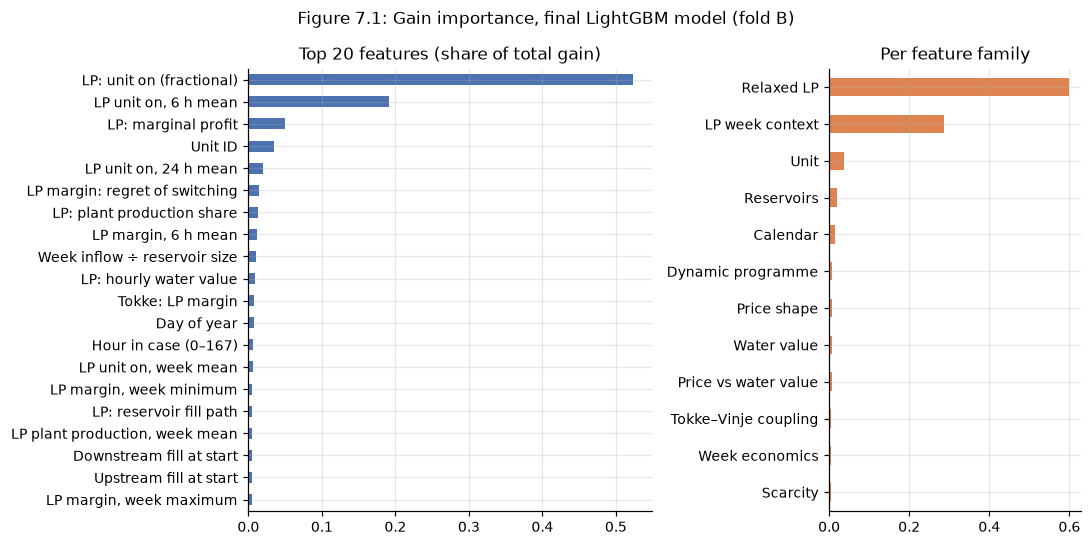

In [19]:
# Figure 7.1: gain importance per feature and per family
gain = models.importance(model, names).rename(index=label).sort_values()
by_family = models.importance(model, names).groupby(lambda n: family(n)).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={"width_ratios": [1.6, 1]})
gain.tail(20).plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("Top 20 features (share of total gain)")
by_family.plot.barh(ax=axes[1], color="#DD8452"); axes[1].set_title("Per feature family")
fig.suptitle("Figure 7.1: Gain importance, final LightGBM model (fold B)")
plt.tight_layout(); show_figure("7.1")

**7.2 SHAP values.** We will explain SHAP in plain words: for one prediction, SHAP splits the model's
output (in log-odds) into a contribution from each feature, so that the contributions add up to the prediction. Averaging
the absolute contributions gives an importance per feature, and plotting them against the feature value shows *how* a
feature pushes the prediction. Observations to describe:
- *The two importance measures disagree on the top feature.* By gain, "LP: unit on" is first; by SHAP, "LP: marginal profit" is first (Figure 7.2).
  Explanation: gain measures how much the splits on a feature improve the training loss, and "LP: unit on" makes the first
  and biggest splits (clearly on vs clearly off). SHAP measures how much a feature moves *each individual* prediction, and the
  marginal profit adjusts almost every prediction continuously, also inside the "clearly on" and "clearly off" groups.
- **How to read Figure 7.2** (the report must explain this, because it is not intuitive). Each *row* is one feature.
  Each *dot* is one unit-hour (one unit in one hour of one case), and every unit-hour appears once in every row.
  - *Position (left/right)* = what the feature did to the prediction for that unit-hour. Right of the zero line means
    the feature pushed that unit-hour towards ON (higher probability of running), left means it pushed it towards OFF.
    Far from zero = a strong push.
  - *Colour* = the feature's own value in that unit-hour, compared with its other values: blue = one of the lowest
    values of this feature, red = one of the highest. **Colour says nothing about whether the feature is good or bad,
    and nothing about the prediction by itself.**
  - The meaning comes from combining the two. In the "LP: marginal profit" row, red dots are on the right: when the
    LP finds running very profitable, the model predicts ON. In the "LP: hourly water value" row it is the opposite:
    red dots are on the left, because when the water is very valuable the model predicts OFF (the water is saved).
  - Why the rows look roughly mirrored: SHAP values are measured from the model's average prediction, so a useful
    feature pushes some unit-hours up and others down. Units are ON about half the time, so the two sides are
    about equally large. A wide two-sided row means the feature separates ON from OFF strongly, not that it cancels out.
  - "Unit ID" is drawn in grey: the units are categories, so "low" and "high" values have no meaning.

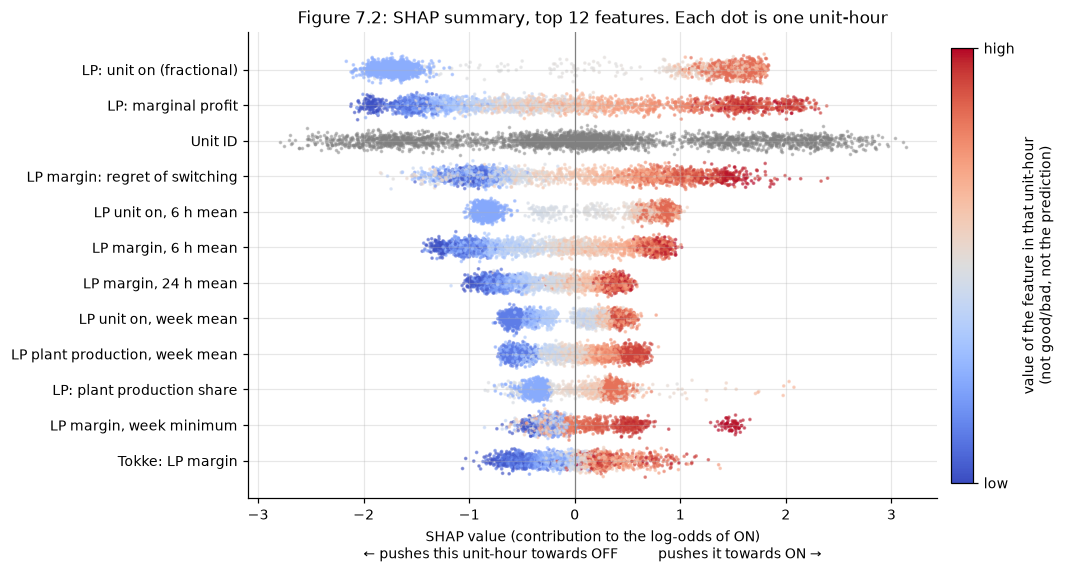

,mean |SHAP|
LP: unit on (fractional),1.586
LP: marginal profit,1.081
Unit ID,1.020
LP margin: regret of switching,0.866
"LP unit on, 6 h mean",0.788
"LP margin, 6 h mean",0.682
"LP margin, 24 h mean",0.438
"LP unit on, week mean",0.390
"LP plant production, week mean",0.382
LP: plant production share,0.344


In [20]:
# SHAP values with LightGBM's built-in TreeSHAP on a random sample of 2021 unit-hours
X_val = X[val_idx].reshape(-1, X.shape[-1])
rows = np.random.default_rng(0).choice(len(X_val), 40_000, replace=False)
contrib = model.booster_.predict(X_val[rows], pred_contrib=True)  # last column = expected value
shap_values, X_sample = contrib[:, :-1], X_val[rows]
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=names).sort_values(ascending=False)

# Figure 7.2: SHAP summary (beeswarm-style): each dot is one unit-hour; position = push towards ON/OFF, colour = feature value (low → high)
top = mean_abs.index[:12][::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, name in enumerate(top):
    j = names.index(name)
    values = X_sample[:, j]
    finite = np.isfinite(values)
    colour = np.full(len(values), 0.5)
    colour[finite] = pd.Series(values[finite]).rank(pct=True).to_numpy()  # rank within this feature: 0 = lowest, 1 = highest
    show = np.random.default_rng(i).choice(len(values), 3000, replace=False)
    jitter = i + np.random.default_rng(i).normal(0, 0.12, len(show))
    if name == "unit":  # categorical: low/high has no meaning, so no colour
        ax.scatter(shap_values[show, j], jitter, color="grey", s=2, alpha=0.4)
    else:
        dots = ax.scatter(shap_values[show, j], jitter, c=colour[show], cmap="coolwarm", vmin=0, vmax=1, s=2, alpha=0.5)
ax.set_yticks(range(len(top)), [label(n) for n in top])
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("SHAP value (contribution to the log-odds of ON)\n← pushes this unit-hour towards OFF          pushes it towards ON →")
bar = fig.colorbar(dots, ax=ax, ticks=[0, 1], fraction=0.03, pad=0.02)
bar.ax.set_yticklabels(["low", "high"]); bar.set_label("value of the feature in that unit-hour\n(not good/bad, not the prediction)")
bar.solids.set_alpha(1)
ax.set_title("Figure 7.2: SHAP summary, top 12 features. Each dot is one unit-hour")
show_figure("7.2")
mean_abs.rename(index=label).head(12).round(3).to_frame("mean |SHAP|")

- *The directions are physically sensible* (Figure 7.2). A high LP marginal profit, a high LP unit-on and a high LP production all
  push towards ON. A high LP water value pushes towards OFF (expensive water is saved). A high DP regret pushes towards ON.
- *The model trusts the LP but not blindly* (Figure 7.3). The effect of the LP's marginal profit is a smooth S-curve centred at
  zero: the model is most sensitive exactly where running is barely profitable or barely unprofitable. "LP: unit on"
  has clusters at 0 and 1 with fractional values in between that the model maps to intermediate probabilities.

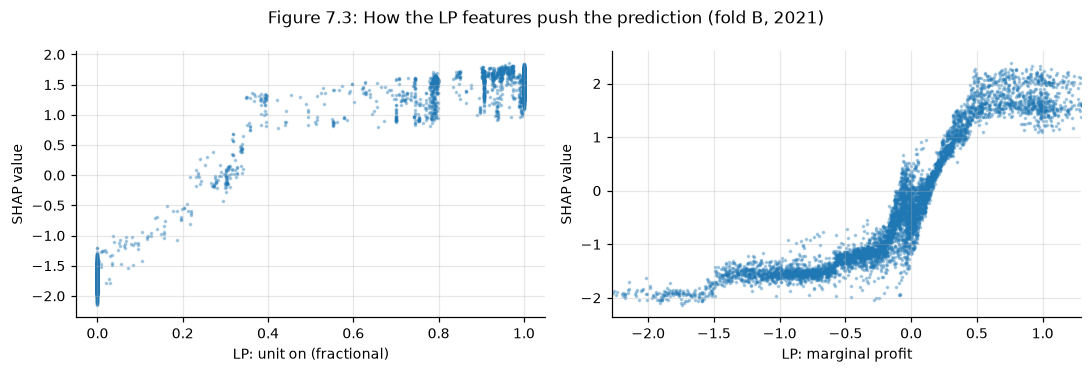

In [21]:
# Figure 7.3: SHAP dependence for the two main LP features
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, name in zip(axes, ["lpb_unit_on", "lpb_margin"]):
    j = names.index(name)
    show = np.random.default_rng(1).choice(len(rows), 6000, replace=False)
    ax.scatter(X_sample[show, j], shap_values[show, j], s=2, alpha=0.3)
    ax.set_xlabel(label(name)); ax.set_ylabel("SHAP value")
    if name == "lpb_margin":
        ax.set_xlim(*np.nanquantile(X_sample[:, j], [0.01, 0.99]))
fig.suptitle("Figure 7.3: How the LP features push the prediction (fold B, 2021)")
plt.tight_layout(); show_figure("7.3")

- Note: we computed SHAP with LightGBM's built-in TreeSHAP (`pred_contrib=True`) instead of the `shap` package.

**7.3 Where the model is right and wrong.**
- *Per unit (Figure 7.4).* Most units score above 0.99. The hardest, with our explanations: Vinje G3 (0.950 in 2020; the third
  identical unit, so whether it runs is often a near-tie with G2, and it is on only 26% of the time); Haukeli (0.97–0.98; a tiny
  4.9 MW unit whose reservoir volume in the data is a constant placeholder, so neither we nor the LP know its real start state);
  Hogga (0.975–0.985; at the bottom of the cascade, so it depends on everything upstream); Lio in 2022 (0.972; driven by a
  minimum-flow requirement). 2020 is the hardest year for most units. Possible explanation: with prices near 9 EUR/MWh and water values
  near zero, many hours are close to indifferent, so small differences decide.

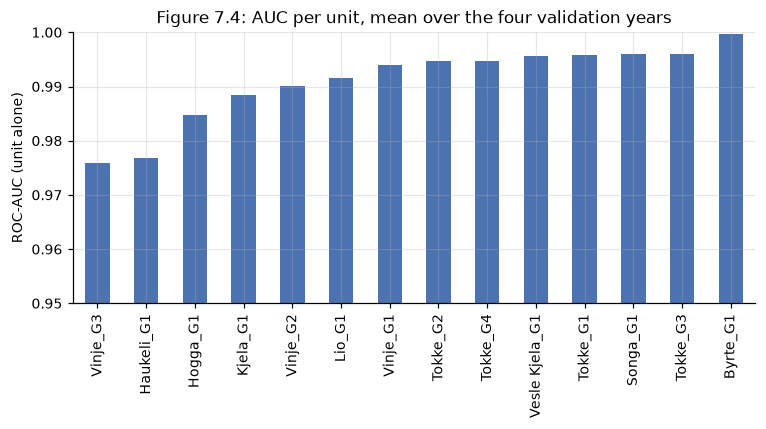

,2020,2021,2022,2019
Hogga_G1,0.9902,0.9813,0.9854,0.9824
Tokke_G1,0.9926,0.9975,0.9983,0.9952
Tokke_G2,0.9896,0.9970,0.9952,0.9973
Tokke_G3,0.9929,0.9974,0.9981,0.9960
Tokke_G4,0.9902,0.9962,0.9968,0.9960
Lio_G1,0.9933,0.9914,0.9830,0.9990
Byrte_G1,0.9996,0.9997,0.9997,0.9995
Vinje_G1,0.9916,0.9951,0.9950,0.9943
Vinje_G2,0.9869,0.9909,0.9924,0.9902
Vinje_G3,0.9620,0.9870,0.9855,0.9692


In [22]:
# Figure 7.4: AUC per unit, mean over folds A–D (final model, saved validation predictions)
per_unit = []
for fold, year in cv.FOLDS.items():
    _, idx = cv.split(data, year)
    per_unit.append(pd.Series(cv.unit_scores(data, idx, np.load(EXP / "exp_046_no_next_week_price" / f"pred_{fold}.npy")), name=year))
per_unit = pd.concat(per_unit, axis=1)
fig, ax = plt.subplots(figsize=(8, 3.2))
per_unit.mean(axis=1).sort_values().plot.bar(ax=ax, color="#4C72B0")
ax.set_ylim(0.95, 1); ax.set_ylabel("ROC-AUC (unit alone)")
ax.set_title("Figure 7.4: AUC per unit, mean over the four validation years")
show_figure("7.4")
per_unit.round(4)

- *Per hour of the horizon (Figure 7.5).* The first hours of each case are the hardest (0.989 at hour 0, rising over the first
  ~10 hours), and the last day is the easiest. Explanations: at the start, SHOP knows which units were already running, but we don't
  (there is no initial on/off state in the data). At the end, decisions are dominated by the +7 d water value, which we know exactly.
  The curve also dips slightly once a day; see the next point.

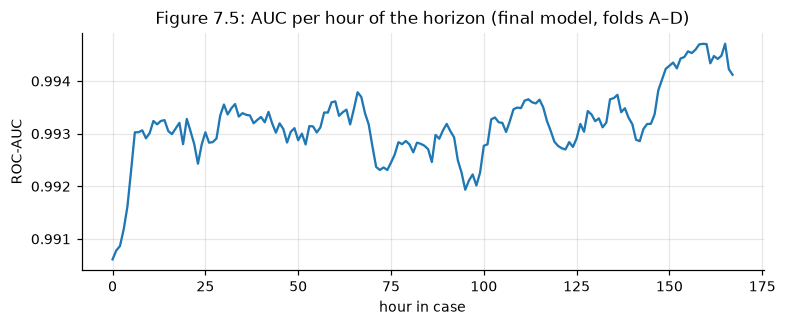

In [23]:
# Figure 7.5: AUC per hour of the 168-hour horizon (all folds pooled)
y_all, p_all = [], []
for fold, year in cv.FOLDS.items():
    _, idx = cv.split(data, year)
    y_all.append(data.Y[idx]); p_all.append(np.load(EXP / "exp_046_no_next_week_price" / f"pred_{fold}.npy"))
y_all, p_all = np.concatenate(y_all), np.concatenate(p_all)
auc_by_hour = [roc_auc_score(y_all[:, :, t].ravel(), p_all[:, :, t].ravel()) for t in range(HOURS)]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(range(HOURS), auc_by_hour)
ax.set_xlabel("hour in case"); ax.set_ylabel("ROC-AUC")
ax.set_title("Figure 7.5: AUC per hour of the horizon (final model, folds A–D)")
show_figure("7.5")

- *The daily dips are at night, not at the switching hours (Table 7.1).* Our first guess was that the dips are the
  hours where units start or stop, since those are the hardest hours to predict. We checked this, and it is wrong:
  - The dips are at 23:00–03:00 UTC (midnight to about 04:00 Norwegian time), with AUC 0.991 against 0.992 in the
    daytime. The difference is small, but it repeats every day.
  - Starts and stops follow the two daily price peaks: units start before the morning peak (04:00–06:00 UTC) and
    the afternoon peak (15:00–16:00), and stop after them (08:00–11:00 and 18:00–23:00). The AUC in the busiest
    start hours is normal, and the per-hour AUC is almost unrelated to how many switches happen in that hour
    (correlation 0.07).
  - What *is* different at night: the simple rule "price > water value" fits the decisions slightly worse (81% vs 83%),
    and the model is unsure (probability between 0.2 and 0.8) slightly more often (7.5% vs 6.6% of unit-hours).
  - Possible explanation: night prices are low and flat, so for many units the decision is not clearly decided by the
    price but by other things, for example whether keeping a unit running through the night is cheaper than stopping
    and restarting it in the morning (start costs), or what the units further up or down the river do. Those are
    the parts the model captures least well. We have not proven this explanation.

In [24]:
# Table 7.1: per hour of day (hours 24–167, so the hard first hours do not distort it): AUC, switches, rule fit, model certainty
t = np.arange(24, HOURS)
hod = t % 24  # cases start at 00:00 UTC, so hour in case mod 24 = hour of day (UTC)
switch = np.zeros_like(y_all, dtype=bool); switch[:, :, 1:] = y_all[:, :, 1:] != y_all[:, :, :-1]
starts = switch & (y_all == 1); stops = switch & (y_all == 0)
cases = np.concatenate([cv.split(data, year)[1] for year in cv.FOLDS.values()])  # same case order as y_all
rule_fit = (week_prices(data)[cases][:, None, :] > upstream_wv(data, 7)[cases][:, :, None]) == y_all
unsure = (p_all > 0.2) & (p_all < 0.8)
per_hour = pd.DataFrame({
    "AUC": np.array(auc_by_hour)[t],
    "Starts (% of unit-hours)": 100 * starts[:, :, t].mean(axis=(0, 1)),
    "Stops (% of unit-hours)": 100 * stops[:, :, t].mean(axis=(0, 1)),
    "'Price > water value' matches (%)": 100 * rule_fit[:, :, t].mean(axis=(0, 1)),
    "Model unsure, 0.2 < p < 0.8 (%)": 100 * unsure[:, :, t].mean(axis=(0, 1)),
}).groupby(hod).mean()
per_hour.index.name = "Hour of day (UTC)"
print(f"Correlation between per-hour AUC and share of switches (hours 24–167): "
      f"{np.corrcoef(np.array(auc_by_hour)[t], switch[:, :, t].mean(axis=(0, 1)))[0, 1]:.2f}")
show_table(per_hour.round({"AUC": 4, **{k: 1 for k in per_hour.columns[1:]}}), "7.1", columns='p{1.8cm}p{1.2cm}p{1.9cm}p{1.9cm}p{2.6cm}p{2.6cm}')

Correlation between per-hour AUC and share of switches (hours 24–167): 0.02


,AUC,Starts (% of unit-hours),Stops (% of unit-hours),'Price > water value' matches (%),"Model unsure, 0.2 < p < 0.8 (%)"
Hour of day (UTC),,,,,
0,0.9927,0.0,0.9,81.4,6.2
1,0.9928,0.1,0.6,81.2,6.3
2,0.9927,0.2,0.3,81.1,6.2
3,0.9929,0.9,0.1,81.5,6.2
4,0.9930,2.3,0.1,82.0,6.1
5,0.9932,3.1,0.0,82.3,5.9
6,0.9934,2.9,0.1,82.5,5.6
7,0.9933,1.3,0.5,82.6,5.5
8,0.9934,0.6,1.0,82.8,5.5


- *Slow optimiser runs (Table 7.2).* The data includes how long SHOP took to solve each case
  (`total_calculation_time`; used only for this analysis, never as a feature). On cases where SHOP took ≥ 900 seconds,
  our AUC is clearly lower than on fast cases in every year (for example 0.932 vs 0.994 in 2022).
  - *Why "possibly a time limit".* The labels were made by SINTEF, not by us: they ran SHOP once per case. About half of the
    slow runs (85 of 174) end at almost the same time, 950–1100 seconds (§2.2), which looks like SINTEF stopped SHOP at a fixed limit
    and kept the best schedule found so far. Such a schedule can be slightly worse than the optimal one. The dataset
    does not say whether there was a limit, so this is our interpretation.
  - *Why we call it "noise in the validation labels".* A label is the correct answer we are scored against: SHOP's
    on/off decision for one unit in one hour. If a slow case was cut off early, some of its labels are not what an
    optimal SHOP would have chosen. Our model learns the optimal behaviour from the many normal cases, so on a cut-off
    case its predictions disagree with the labels and the score drops, even though the model is not the problem.
  - *Why down-weighting did not help (exp 032).* Giving the slow cases less weight in training only changes what the
    model learns. It cannot change the labels the model is scored against, and the model already learns mostly from
    the normal cases (slow cases are only about 6% of the training cases). So there was nothing to gain.
  - *Alternative explanation.* The slow cases may simply be hard: several schedules are almost equally profitable,
    which is exactly why SHOP needed so long to choose. Then the labels are not "wrong" but close to arbitrary.
    Both explanations lead to the same conclusion: this part of the error is a limit of the data, not something a
    better model can remove.

In [25]:
# Table 7.2: AUC on cases from fast and slow optimiser runs
seconds = pd.read_csv(ROOT / "data/kernel/Unit_commitment_decisions.csv", usecols=["total_calculation_time"])["total_calculation_time"].to_numpy()
rows = []
for fold, year in cv.FOLDS.items():
    _, idx = cv.split(data, year)
    pred = np.load(EXP / "exp_046_no_next_week_price" / f"pred_{fold}.npy")
    for group, mask in [("fast (< 300 s)", seconds[idx] < 300), ("slow (≥ 900 s)", seconds[idx] >= 900)]:
        if mask.sum() >= 5:
            rows.append({"year": year, "cases": group, "n": int(mask.sum()),
                         "AUC": round(roc_auc_score(data.Y[idx][mask].ravel(), pred[mask].ravel()), 4)})
show_table(pd.DataFrame(rows).pivot(index="year", columns="cases", values=["n", "AUC"]), "7.2")

n                           AUC               
cases fast (< 300 s) slow (≥ 900 s) fast (< 300 s) slow (≥ 900 s)
year                                                             
2019           322.0           32.0         0.9948         0.9896
2020           345.0           15.0         0.9895         0.9760
2021           351.0            7.0         0.9953         0.9898
2022           344.0           17.0         0.9953         0.9341

**7.4 One example week (Figure 7.6).** Labels, model predictions and the LP's "unit on" for four units in a busy 2021 week
(1 April; chosen automatically as a week with many on/off switches). What to point out:

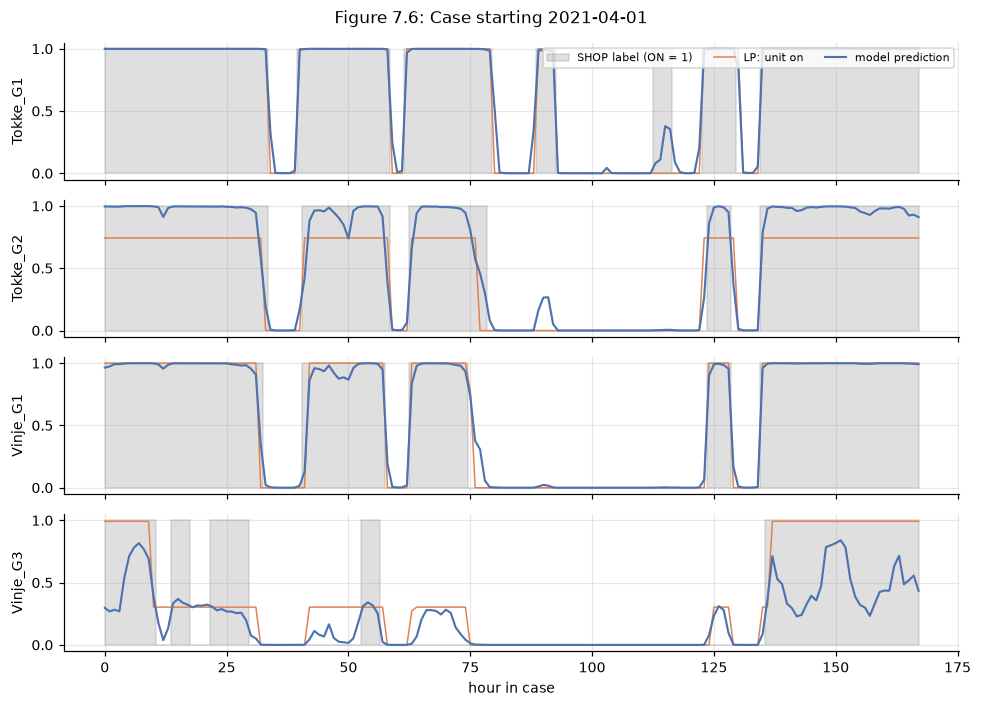

In [26]:
# Figure 7.6: one example week in 2021: labels, model and LP for four units
example_units = ["Tokke_G1", "Tokke_G2", "Vinje_G1", "Vinje_G3"]
cols = [data.units.index(u) for u in example_units]
switches = np.abs(np.diff(data.Y[val_idx][:, cols], axis=2)).sum(axis=(1, 2))
week = int(np.argsort(switches)[len(switches) * 9 // 10])  # a busy but typical week: 90th percentile of label switches
case = val_idx[week]
fig, axes = plt.subplots(4, 1, figsize=(9, 6.5), sharex=True)
for ax, unit in zip(axes, example_units):
    u = data.units.index(unit)
    ax.fill_between(range(HOURS), data.Y[case, u], step="mid", alpha=0.25, color="grey", label="SHOP label (ON = 1)")
    ax.plot(lp_on[case, u], color="#DD8452", lw=1, label="LP: unit on")
    ax.plot(pred_B[week, u], color="#4C72B0", lw=1.4, label="model prediction")
    ax.set_ylabel(unit); ax.set_ylim(-0.05, 1.05)
axes[0].legend(ncol=3, fontsize=7, loc="upper right")
axes[-1].set_xlabel("hour in case")
fig.suptitle(f"Figure 7.6: Case starting {data.starts[case]:%Y-%m-%d}")
plt.tight_layout(); show_figure("7.6")

- *The LP gets the big blocks right.* For Tokke G1 and Vinje G1, the LP's on/off pattern already matches most of SHOP's blocks, and the model follows it.
- *The model sharpens the LP where the LP is fractional.* For Tokke G2 the LP says "0.75 of a unit" for whole blocks; the model turns this into
  close to 1 when SHOP runs the unit and close to 0 when it does not.
- *Uncertainty shows up where it should.* The dips in the model's prediction (e.g. Vinje G1 around hours 10 and 50) are hours where the decision
  is close; ranking them in the middle costs little AUC.
- *The weakest unit, Vinje G3, is visibly hard.* SHOP runs it in short blocks in the first 60 hours that neither the LP nor the model
  predicts, and at the end of the week the LP says ON while the model stays low. This illustrates the near-tie between identical units
  discussed in 7.3: the model has learned that the LP over-commits the third Vinje unit, so it does not trust it.

## 8. Results

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

A short section with the final numbers in one table (Table 8.1): per-fold validation AUC, the mean, the locked 2018 holdout,
and the public leaderboard score for both final models, plus the highest virtual team for reference.

In [27]:
# Table 8.1: all results in one table (per-fold scores: Tables 5.1 and 8.2)
holdout = results.dropna(subset=["holdout_2018"]).drop_duplicates("name", keep="last").set_index("name")["holdout_2018"]
public_lb = {"exp_017_lp_minflow": 0.99042, "exp_021_lp_commitment": 0.99067, "exp_024_lp_shop": 0.99099,
             "exp_029_main_river": 0.99414, "exp_030_xgb_main_river": 0.99429,
             "exp_038_dispatch_context": 0.99554, "exp_041_xgb_dispatch_context": 0.99552,
             "exp_039_dispatch_capacity": 0.99559, "exp_040_xgb_dispatch_capacity": 0.99566,
             "exp_046_no_next_week_price": 0.99558, "exp_047_xgb_no_next_week_price": 0.99555}  # final files; from journal.md
mean_of = lambda name: cv_rows.loc[name, "mean"]
rows = [  # (group, predictor, mean A–D, holdout 2018, public LB)
    ("Without learning", "Economic rule: price − upstream water value", table_51.loc["Rule: price − upstream water value (+7 d)", "mean"], None, None),
    ("", "Relaxed LP alone: units on", table_51.loc["Relaxed LP alone: unit on", "mean"], None, None),
    ("", "Relaxed LP alone: margin", table_51.loc["Relaxed LP alone: marginal profit", "mean"], None, None),
]
stages = [("exp_001_baseline_v2", "001: economic features"), ("exp_002_no_raw_eur", "002: − raw EUR levels"),
          ("exp_007_hydro_pressure", "007: + reservoir pressure"), ("exp_008_relaxed_dp", "008: + dynamic programme"),
          ("exp_009_tokke_vinje", "009: + Tokke–Vinje coupling"), ("exp_013_relaxed_lp", "013: + relaxed LP"),
          ("exp_014c_without_hydro_pressure", "014c: − reservoir pressure"), ("exp_017_lp_minflow", "017: LP + minimum flows"),
          ("exp_021_lp_commitment", "021: LP + start costs"), ("exp_024_lp_shop", "024: LP + production curves, spill costs"),
          ("exp_029_main_river", "029: LP routing fix"), ("exp_037_terminal_efficiency", "037: LP efficient end value")]
for i, (name, label) in enumerate(stages):
    rows.append(("Development (LightGBM)" if i == 0 else "", label, mean_of(name), None, public_lb.get(name)))
rows += [
    ("Other predictors, final features", "Logistic regression (042)", mean_of("exp_042_logistic_final"), None, None),
    ("", "Neural network, MLP (044)", mean_of("exp_044_mlp_final"), None, None),
    ("", "Neural network, MLP tuned (045c)", mean_of("exp_045c_mlp_slow_lr"), None, None),
    ("", "Random forest (043)", mean_of("exp_043_random_forest_final"), None, None),
    ("Larger fit, not selected", "LightGBM, 039: 60% rows, 2200 trees", mean_of("exp_039_dispatch_capacity"), holdout["exp_039_dispatch_capacity"], public_lb["exp_039_dispatch_capacity"]),
    ("", "XGBoost, 040: 60% rows, 2200 trees", mean_of("exp_040_xgb_dispatch_capacity"), holdout["exp_040_xgb_dispatch_capacity"], public_lb["exp_040_xgb_dispatch_capacity"]),
    ("With next week's price, replaced", "LightGBM, 038: + LP week context", mean_of("exp_038_dispatch_context"), holdout["exp_038_dispatch_context"], public_lb["exp_038_dispatch_context"]),
    ("", "XGBoost, 041", mean_of("exp_041_xgb_dispatch_context"), holdout["exp_041_xgb_dispatch_context"], public_lb["exp_041_xgb_dispatch_context"]),
    ("Final models", "LightGBM, 046: 038 without next week's price (final 1)", mean_of("exp_046_no_next_week_price"), holdout["exp_046_no_next_week_price"], public_lb["exp_046_no_next_week_price"]),
    ("", "XGBoost, 047 (final 2)", mean_of("exp_047_xgb_no_next_week_price"), holdout["exp_047_xgb_no_next_week_price"], public_lb["exp_047_xgb_no_next_week_price"]),
    ("", "Blend of 046 and 047 (50/50)", table_51.loc["Blend 50/50 of exp 046 and 047", "mean"], None, None),
    ("Reference", "Highest virtual team (VT1)", None, None, 0.99040),
]
fmt = lambda v, digits: "—" if v is None or pd.isna(v) else f"{v:.{digits}f}"
overall = pd.DataFrame([(g, p, fmt(m, 4), fmt(h, 4), fmt(lb, 5)) for g, p, m, h, lb in rows],
                       columns=["", "Predictor", "mean A–D", "holdout 2018", "public LB"])
show_table(overall, "8.1", columns=r">{\raggedright\arraybackslash}p{0.2\linewidth}>{\raggedright\arraybackslash}p{0.42\linewidth}lll")
overall

,,Predictor,mean A–D,holdout 2018,public LB
0,Without learning,Economic rule: price − upstream water value,0.8698,—,—
1,,Relaxed LP alone: units on,0.9587,—,—
2,,Relaxed LP alone: margin,0.9604,—,—
3,Development (LightGBM),001: economic features,0.9593,—,—
4,,002: − raw EUR levels,0.9642,—,—
5,,007: + reservoir pressure,0.9652,—,—
6,,008: + dynamic programme,0.9663,—,—
7,,009: + Tokke–Vinje coupling,0.9789,—,—
8,,013: + relaxed LP,0.9829,—,—
9,,014c: − reservoir pressure,0.9827,—,—


In [28]:
# Table 8.2: per-fold results of the final models
final = pd.DataFrame({
    "LightGBM (exp 046, Short_notebook_1)": {**cv_rows.loc["exp_046_no_next_week_price", ["A", "B", "C", "D", "mean"]].to_dict(),
                                              "holdout_2018": holdout["exp_046_no_next_week_price"], "public LB": public_lb["exp_046_no_next_week_price"]},
    "XGBoost (exp 047, Short_notebook_2)": {**cv_rows.loc["exp_047_xgb_no_next_week_price", ["A", "B", "C", "D", "mean"]].to_dict(),
                                             "holdout_2018": holdout["exp_047_xgb_no_next_week_price"], "public LB": public_lb["exp_047_xgb_no_next_week_price"]},
    "Highest virtual team (VT1)": {"public LB": 0.99040},
}).T
final.columns = ["A (2020)", "B (2021)", "C (2022)", "D (2019)", "mean A–D", "holdout 2018", "public LB"]
show_table(final.apply(lambda col: col.map(lambda v: "—" if pd.isna(v) else f"{v:.5f}" if col.name == "public LB" else f"{v:.4f}")), "8.2")

,A (2020),B (2021),C (2022),D (2019),mean A–D,holdout 2018,public LB
"LightGBM (exp 046, Short_notebook_1)",0.9891,0.9952,0.9934,0.9941,0.9929,0.9895,0.99558
"XGBoost (exp 047, Short_notebook_2)",0.9884,0.9951,0.9934,0.9936,0.9926,0.9895,0.99555
Highest virtual team (VT1),—,—,—,—,—,—,0.99040


What to say:
- Both models clear the highest virtual team (0.99040) on the public leaderboard by about 0.004.
- The 2018 holdout (0.9877 / 0.9876) lies within the range of the validation folds (0.9868–0.9941), so we see no sign that
  our choices overfitted the four folds.
- The public leaderboard score is higher than our validation mean. Possible explanation: 2023–2024 has more normal prices than our
  hardest validation years (2020, 2022).
- Caveat: the final grade uses the private leaderboard, which we cannot see; differences of ±0.001 between our two models
  are noise.
- Reproducibility: both short notebooks run from the raw data in about 9 minutes on a laptop and reproduce our submitted files
  byte for byte.

## 9. Discussion and lessons learned

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

We will close with the lessons we would pass on, each with its evidence:
- **Domain knowledge beat model choice.** Physics-based features added about +0.03 AUC (0.959 → 0.991), while switching between
  LightGBM and XGBoost, tuning, per-unit models and blends each changed the score by less than 0.002.
- **Imitating an optimiser is best done with (a simplified copy of) the optimiser.** The relaxed LP turned a learning problem
  into a correction problem.
- **New information beats re-expressed information.** Features that only rearranged existing inputs never helped; features that
  added physics (reservoir limits, coupling, minimum flows) always did.
- **Check the physics before tuning.** One wrong river in the routing cost more than all tuning could recover (the Hyljelihyl bug).
- **A strict validation protocol kept us honest.** Year-based folds with an embargo, a seed-noise threshold and a locked holdout
  year meant that most of our "ideas" were correctly rejected.

**Limitations.** Some labels may be suboptimal (slow optimiser runs); the LP is linear (fixed head, linearised efficiency) and has no
true on/off decisions; overlapping cases disagree on 12% of hours, which bounds what any model can reach; and we did not try neural
networks.

**Future work.** A small neural network (1D CNN) over the LP's hourly outputs as a second, more different model; a better
start-state estimate for the first hours of each case; and a closer copy of SHOP (head-dependent production, true unit commitment
with a time limit).

## 10. References

> 📝 **Disposition**: what this section will say. To be rewritten as final prose once we agree on the content.

To be completed with full citations:
- SINTEF Energy Research: task description and `Dataset_definitions_and_explanation.pdf`.
- Barjaktarevic et al., *An Evaluation of Neural Network Architectures for Predicting Hydro Unit Commitment Decisions*, EEM 2026,
  DOI 10.1109/eem68581.2026.11589730.
- Reite et al. (source of the scarcity-coefficient interpretation of the water values); see `research/03`.
- Grinsztajn, Oyallon and Varoquaux (2022), *Why do tree-based models still outperform deep learning on tabular data?*, NeurIPS.
- Ke et al. (2017), LightGBM; Chen and Guestrin (2016), XGBoost; Lundberg and Lee (2017), SHAP.
- SciPy / HiGHS for the linear programs.